# Uncertainty-Aware Predictive Compensation of Respiratory Motion for Delayed Robotic Intervention
### Notebook — PICSDB · target: IEEE JAC-ECC 2026

> **All target displacements and robot results in this notebook are SIMULATED.** The datasets provide physiological respiratory *surrogate* waveforms, not measured organ displacement (unless displacement ground truth is explicitly verified, which it is not here). Nothing below is physical-robot or clinical validation.

## Abstract
We study whether *predictive uncertainty* helps compensate latency in a simulated respiratory-tracking robot. A causal pipeline forecasts the respiratory surrogate 100–500 ms ahead (persistence, ridge-AR, Kalman, probabilistic LSTM/TCN, deep ensemble, split-conformal intervals), assesses calibration, drives a 1-DOF simulated actuator with five controllers under 0–500 ms observation delay, and tests whether σ warns of future tracking failure. The contribution investigated is **uncertainty-aware compensation under latency and distribution shift** — not the novelty of respiratory forecasting itself. No positive result is assumed; negative results are reported.

## Motivation: why latency and uncertainty
Sensing, communication and actuation delay mean a controller acts on stale measurements; with a ~0.2–0.5 Hz breathing cycle, a 300 ms delay is a sizeable phase error. Forecasting can compensate, but point forecasts hide *how wrong* they may be: when the forecast is unreliable (irregular breathing, artifacts, population shift) trusting it can be worse than the delayed measurement. Predictive uncertainty offers a principled way to blend forecast and measurement and to flag likely failures.

## Dataset and role
**Preterm Infant Cardio-Respiratory Signals Database (PICSDB)** (PhysioNet, v1.0.0): long recordings from preterm infants with ECG and respiration (record names and rates **verified from headers at runtime**). **Role:** small-cohort, high-respiratory-rate distribution shift; leave-one-infant-out evaluation; reduced-size models and transparent baselines because of data scarcity.

## Research questions and hypotheses
* **RQ1** forecasting accuracy at 100–500 ms · **RQ2** calibration of uncertainty and whether it grows with error · **RQ3** can σ predict future tracking failure under delay · **RQ4** does uncertainty-aware control beat reactive / predictive / fixed-blend / Kalman · **RQ5** robustness across populations.
* Hypotheses (tested, not assumed): H1: ensemble forecasts beat persistence at ≥300 ms even for neonatal rhythms (faster dynamics make this harder). H2: σ correlates with |error|. H3: calibration degrades on held-out infants. H4: uncertainty-aware blending improves tracking only if σ is informative.

## Pipeline
```mermaid
flowchart LR
  A[PhysioNet records + header verification] --> B[Causal band-pass + 20 Hz ZOH]
  B --> C[Subject-level split -> causal windows]
  C --> D[Forecasters: persistence / ridge / Kalman / LSTM / TCN / ensemble]
  D --> E[Uncertainty: aleatoric + epistemic + conformal]
  D --> F[Simulated target A*z -> 1-DOF robot]
  E --> G[Controllers: reactive / predictive / blend / Kalman / UA-blend]
  F --> G --> H[Tracking metrics + failure warning AUC]
  H --> I[Subject-level statistics, ablations, report]
```
Text version: `records -> preprocess(causal) -> split(subjects) -> windows -> models -> uncertainty -> simulated robot -> controllers -> failure prediction -> statistics -> report`.

## Limitations and intended contribution
Surrogate-driven simulation only; small cohorts; segments chosen for compute; conformal guarantees do not strictly hold under temporal dependence/shift. Intended contribution: a transparent, leakage-controlled, reproducible benchmark of whether uncertainty improves latency compensation and failure warning. See the generated `limitations_and_assumptions.md`.

## How to use
Set `MODE` to `"smoke"` (tiny debug), `"fast"` (real data, reduced compute) or `"full"` (all real data, final experiment) in the configuration cell below, then *Run all*. Every run writes to a new timestamped folder.

## Run configuration
Smoke vs. full mode, dataset limits, epochs, batch size and output directory are set here.

In [1]:
# ======================= RUN CONFIGURATION (edit here) =======================
import numpy as np
MODE = "full"                     # "smoke" (tiny debug) | "fast" (real data, reduced compute) | "full" (all real data, final run)
import os
ON_KAGGLE = os.path.exists("/kaggle/working")   # Kaggle: write to /kaggle/working so files survive "Save Version"
_BASE = "/kaggle/working" if ON_KAGGLE else "."
SEED = 42
RESULTS_BASE = f"{_BASE}/results/picsdb"   # a NEW timestamped sub-folder is created for every run
DATA_DIR = f"{_BASE}/data/picsdb"          # dataset download location (Colab or local)
RESUME_RUN = None                 # e.g. "full_20260101_120000" to continue writing into an existing run
ALLOW_OVERWRITE = False           # files from earlier sessions are never overwritten unless True
RUN_RECURSIVE_WGET = False        # True -> run the full recursive wget cell (large, slow; the parallel selective downloader is faster)
DL_WORKERS = 16                   # parallel download threads
USE_CACHE = True                  # reuse per-fold trained models when RESUME_RUN points at an earlier run

DATASET = "PICSDB"
DB_URL = "https://physionet.org/files/picsdb/1.0.0/"
DB_PAGE = "https://physionet.org/content/picsdb/1.0.0/"
EXPECTED_N_RECORDS = None       # from documentation; only used for a warning
RESP_REGEX = r"resp"              # candidate respiratory channel names (verified against headers at runtime)
RESP_PREFERRED = r"resp"

# preprocessing
FS_MODEL = 20; FILTER_ORDER = 4; BAND = (0.1, 3.0); ALT_BANDS = [(0.1, 2.0), (0.2, 3.0), (0.1, 5.0)]
MAX_GAP_S = 0.25; FLAT_S = 2.0; WARMUP_S = 10.0; CHUNK_S = 300; MIN_SEG_S = 60; MIN_VALID_FRAC = 0.7
# windows
HIST = 100; HORIZONS_STEPS = [2, 4, 6, 8, 10]          # 5 s history; 100-500 ms at 20 Hz
# models
SIGMA_MIN = 1e-3; LR = 3e-3; WD = 1e-5; LAYERS = 1; BATCH = 1024
RIDGE_ALPHAS = [1e-3, 1e-2, 1e-1, 1, 10, 100, 1000]; KF_Q = [1e-2, 1e-1, 1, 10, 100]; KF_R = [1e-3, 1e-2, 1e-1, 1]
# robot / controllers
AMPLITUDE_MM = 5.0; AMPLITUDES_MM = [2.0, 5.0, 10.0]; TAU_ACT = 0.2; D_CMD = 0; UMAX_FACTOR = 6.0; TRANSIENT_S = 1.0; MIN_RUN = 100
DELAYS_STEPS = [0, 2, 4, 6, 8, 10]                      # 0..500 ms observation delay
W_GRID = np.linspace(0, 1, 11); C_GRID = [0.25, 0.5, 1, 2, 4, 8]
BOOT_SCORES = ["sigma_total", "abs_velocity", "last_forecast_error"]   # scores that get subject-bootstrap CIs
EPS_FRAC = 0.2; EPS_SENS = [0.1, 0.2, 0.3]; FAIL_CTRLS = ["predictive", "reactive", "uncertainty_aware"]

MODE_SETTINGS = {
    "smoke": dict(EPOCHS=3, ENS_SIZE=2, HIDDEN=32, TCN_CH=16, TRAIN_STRIDE=8, N_BOOT=100, N_BOOT_FAIL=30, PATIENCE=2, VAL_SUB=4, FAIL_STRIDE=8, MAX_INFANTS=4, RECS_PER_INFANT=1, START_MIN=5, SEG_MIN=10, N_FOLDS=2),
    "fast":  dict(EPOCHS=12, ENS_SIZE=3, HIDDEN=48, TCN_CH=24, TRAIN_STRIDE=4, N_BOOT=300, N_BOOT_FAIL=100, PATIENCE=3, VAL_SUB=3, FAIL_STRIDE=4, MAX_INFANTS=None, RECS_PER_INFANT=1, START_MIN=5, SEG_MIN=20, N_FOLDS=3),
    "full":  dict(EPOCHS=30, ENS_SIZE=5, HIDDEN=64, TCN_CH=32, TRAIN_STRIDE=4, N_BOOT=1000, N_BOOT_FAIL=200, PATIENCE=4, VAL_SUB=2, FAIL_STRIDE=2, MAX_INFANTS=None, RECS_PER_INFANT=None, START_MIN=5, SEG_MIN=60, N_FOLDS=None),
}
globals().update(MODE_SETTINGS[MODE])
CFG_ALL = {k: (v.tolist() if hasattr(v, "tolist") else v) for k, v in dict(globals()).items() if k.isupper() and not k.startswith("_")}
print("MODE =", MODE, {k: MODE_SETTINGS[MODE][k] for k in ("EPOCHS", "ENS_SIZE", "TRAIN_STRIDE")})

MODE = full {'EPOCHS': 30, 'ENS_SIZE': 5, 'TRAIN_STRIDE': 4}


# Section B — Environment setup
Installs/imports packages, checks CUDA/RAM, fixes random seeds, creates a **new timestamped results directory** (nothing is overwritten silently) and defines logging/saving helpers.

In [2]:
%pip install -q wfdb statsmodels tqdm seaborn requests psutil

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 7.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, sys, json, time, math, re, random, platform, warnings, datetime, shutil, threading, pickle, hashlib
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import numpy as np, pandas as pd
import scipy, scipy.signal as sps
from scipy import stats as sstats
from scipy.linalg import solve_discrete_are
import matplotlib, matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             brier_score_loss, confusion_matrix)
import statsmodels
from statsmodels.stats.multitest import multipletests
import wfdb, requests, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from IPython.display import display, Markdown
try:
    import psutil
except ImportError:
    psutil = None

warnings.filterwarnings("default")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int) -> None:
    """Seed python, numpy and torch (deterministic as far as practical)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed(SEED)

ENV = dict(python=sys.version.split()[0], platform=platform.platform(), numpy=np.__version__, pandas=pd.__version__,
           scipy=scipy.__version__, sklearn=sklearn.__version__, statsmodels=statsmodels.__version__, wfdb=wfdb.__version__,
           torch=torch.__version__, matplotlib=matplotlib.__version__, device=str(DEVICE),
           cuda_available=torch.cuda.is_available(),
           ram_total_gb=round(psutil.virtual_memory().total/2**30, 2) if psutil else None,
           ram_available_gb=round(psutil.virtual_memory().available/2**30, 2) if psutil else None, seed=SEED, mode=MODE)
print(json.dumps(ENV, indent=2))
if DEVICE.type == "cpu" and MODE == "full": print("WARNING: MODE='full' on CPU will be very slow. Use a GPU runtime (Kaggle T4/P100) or MODE='fast'.")

{
  "python": "3.13.15",
  "platform": "Linux-6.18.48+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "scipy": "1.16.3",
  "sklearn": "1.6.1",
  "statsmodels": "0.15.0",
  "wfdb": "4.3.1",
  "torch": "2.11.0+cu128",
  "matplotlib": "3.10.0",
  "device": "cuda",
  "cuda_available": true,
  "ram_total_gb": 31.35,
  "ram_available_gb": 29.71,
  "seed": 42,
  "mode": "full"
}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [4]:
# ---- results directory (never overwrites a previous run silently) ----
RUN_NAME = RESUME_RUN or f"{MODE}_{datetime.datetime.now():%Y%m%d_%H%M%S}"
OUT = Path(RESULTS_BASE) / RUN_NAME
if RESUME_RUN is None and OUT.exists():
    raise FileExistsError(f"{OUT} already exists; choose another RUN_NAME or set RESUME_RUN.")
for sub in ["figures", "tables", "models", "logs"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
_WRITTEN = set()          # files written in THIS session (these may be refreshed on cell re-run)
STATUS = {}               # experiment name -> "RUN" or "NOT RUN: reason"
CAPTIONS = {}

def log(msg: str) -> None:
    line = f"[{datetime.datetime.now():%H:%M:%S}] {msg}"
    print(line)
    with open(OUT / "logs" / "run_log.txt", "a") as fh:
        fh.write(line + "\n")

def mark(name: str, status: str = "RUN") -> None:
    STATUS[name] = status
    log(f"STATUS {name}: {status}")

def _guard(path: Path) -> None:
    if path.exists() and str(path) not in _WRITTEN and not ALLOW_OVERWRITE:
        raise FileExistsError(f"{path} exists from an earlier session; set ALLOW_OVERWRITE=True to replace it.")
    _WRITTEN.add(str(path))

def df_to_md(df: pd.DataFrame, floatfmt: str = "{:.4g}") -> str:
    cols = list(df.columns)
    rows = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        rows.append("| " + " | ".join(floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + " |")
    return "\n".join(rows)

def save_table(df: pd.DataFrame, name: str, top_level: bool = True) -> None:
    """Save CSV (results root if top_level) and a Markdown copy in tables/."""
    p = (OUT if top_level else OUT / "tables") / f"{name}.csv"; _guard(p); df.to_csv(p, index=False)
    m = OUT / "tables" / f"{name}.md"; _guard(m); m.write_text(df_to_md(df))

def save_json(obj, name: str) -> None:
    p = OUT / name; _guard(p); p.write_text(json.dumps(obj, indent=2, default=str))

def savefig(fig, name: str, caption: str) -> None:
    """Save a figure as 300-DPI PNG and PDF, record its caption."""
    for ext in ["png", "pdf"]:
        p = OUT / "figures" / f"{name}.{ext}"; _guard(p); fig.savefig(p, dpi=300, bbox_inches="tight")
    CAPTIONS[name] = caption; plt.show()

plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8, "figure.dpi": 110})
sns.set_style("whitegrid")
save_json(dict(CFG_ALL=CFG_ALL, ENV=ENV), "config.json")
log(f"Output directory: {OUT}")

[17:23:01] Output directory: /kaggle/working/results/picsdb/full_20261010_172301


## Dataset-specific hooks
Record naming, cohort labels, subset selection for smoke/full mode and fold construction for **PICSDB**.

In [5]:
# ---------------- dataset-specific hooks (record naming, cohorts, subset selection, folds) ----------------
def _rng(offset=0): return np.random.RandomState(SEED + offset)
def _split_counts(n, f_test, f_val):
    nt = max(1, int(round(n * f_test))); nv = max(1, int(round(n * f_val))); assert n - nt - nv >= 1, "too few subjects for train/val/test"; return nt, nv

def subject_of(rec: str) -> str:
    m = re.match(r"^(slp\d+)[a-z]?$", Path(rec).name, re.I)                  # infant id; several records per infant share it (verify against the README!)
    return m.group(1).lower() if m else Path(rec).name
def group_of(rec: str, row: dict) -> str: return "infant"
def select_subset(df):
    df = df.assign(subject=df["record"].map(subject_of)); subs = sorted(df.subject.unique())
    if MAX_INFANTS is not None and len(subs) > MAX_INFANTS: subs = sorted(_rng().choice(subs, MAX_INFANTS, replace=False).tolist())
    out = []
    for s in subs:
        recs = sorted(df[df.subject == s]["record"]); out += recs[:RECS_PER_INFANT] if RECS_PER_INFANT else recs
    return out
def segment_for(row):
    dur = float(row["duration_s"]); s = min(START_MIN * 60.0, max(dur - SEG_MIN * 60.0, 0.0)); return (s, min(SEG_MIN * 60.0, dur - s))   # chunked streaming reads, never the whole file
def build_folds(subjects, info):
    subs = sorted(subjects); n = len(subs); assert n >= 3, "leave-one-infant-out needs >= 3 infants"
    idx = list(range(n)) if N_FOLDS is None else list(range(min(N_FOLDS, n)))
    return [dict(fold=k, train=[s for j, s in enumerate(subs) if j not in (k, (k + 1) % n)], val=[subs[(k + 1) % n]], test=[subs[k]], test_group={subs[k]: "held_out_infant"}) for k in idx]
def DATASET_EDA_EXTRA():
    print("Verified channel(s):", INV["resp_name"].dropna().unique(), "| sampling rates:", INV["fs"].unique())
    print(f"Records per infant: {INV.groupby('subject').size().to_dict()}")
    print("Band validation: compare the fraction of spectral power inside each candidate passband (BAND_CHECK above). Neonatal respiratory rates are much higher than adults', so the default band is widened to", BAND, "-- confirm with the printed peak frequencies; the narrower adult-style band is an ablation.")

# Section C — Dataset download
Official PhysioNet files are fetched with `wget` (optional full recursive download) or with the **selective downloader** below, which first fetches `RECORDS` and all `.hea` headers (small), inventories them, and downloads signal (`.dat`) files only for the records selected for this run. No folder layout is assumed: the database root is *discovered* by locating `RECORDS`.

In [6]:
# Optional: full recursive download exactly as in the study protocol (may be large; see README). Set RUN_RECURSIVE_WGET=True in the config cell.
if RUN_RECURSIVE_WGET:
    !wget -r -N -c -np -P {DATA_DIR} {DB_URL}

In [7]:
def http_download(url: str, dest: Path, retries: int = 3, timeout: int = 60) -> Path:
    """Download url -> dest (resumable at file level, atomic rename). Raises a descriptive error on failure."""
    dest = Path(dest); dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    last = None
    for a in range(retries):
        try:
            with _session().get(url, stream=True, timeout=timeout) as r:
                r.raise_for_status()
                tmp = dest.with_name(dest.name + ".part")
                with open(tmp, "wb") as fh:
                    for chunk in r.iter_content(1 << 20):
                        fh.write(chunk)
                tmp.replace(dest)
                return dest
        except requests.RequestException as e:
            last = e; time.sleep(2 * (a + 1))
    raise RuntimeError(f"Download failed: {url} ({last}). Fallback: download the file manually (or run the recursive wget cell) "
                       f"and place it in {dest.parent}. No synthetic substitute will be used.")

_tls = threading.local()
def _session():
    """One keep-alive HTTP session per thread (avoids a new TLS handshake for every small file)."""
    if not hasattr(_tls, "s"):
        _tls.s = requests.Session(); _tls.s.mount("https://", requests.adapters.HTTPAdapter(pool_connections=4, pool_maxsize=4, max_retries=0))
    return _tls.s

def parallel_download(jobs, workers: int = 16, desc: str = "download") -> None:
    """jobs = [(url, dest)]. Downloads concurrently; raises ONE RuntimeError listing every failure (no silent skips)."""
    jobs = [(u, Path(d)) for u, d in jobs if not (Path(d).exists() and Path(d).stat().st_size > 0)]
    if not jobs: return
    errs = []
    with ThreadPoolExecutor(max_workers=workers) as ex:
        futs = {ex.submit(http_download, u, d): (u, d) for u, d in jobs}
        for fu in tqdm(as_completed(futs), total=len(futs), desc=desc):
            try: fu.result()
            except Exception as e: errs.append(f"{futs[fu][0]}: {e}")
    if errs: raise RuntimeError(f"{len(errs)} of {len(jobs)} downloads failed:\n" + "\n".join(errs[:10]))

def find_db_root(base: Path):
    cands = sorted(Path(base).rglob("RECORDS"), key=lambda p: len(p.parts))
    return cands[0].parent if cands else None

DATA_DIR = Path(DATA_DIR); DATA_DIR.mkdir(parents=True, exist_ok=True)
DB_ROOT = find_db_root(DATA_DIR)
if DB_ROOT is None:
    http_download(DB_URL + "RECORDS", DATA_DIR / "RECORDS")
    DB_ROOT = find_db_root(DATA_DIR)
assert DB_ROOT is not None, "RECORDS file could not be located or downloaded."
RECORDS = [l.strip() for l in (DB_ROOT / "RECORDS").read_text().split() if l.strip()]
log(f"Database root: {DB_ROOT}; records discovered in official RECORDS: {len(RECORDS)}")
if EXPECTED_N_RECORDS is not None and len(RECORDS) != EXPECTED_N_RECORDS:
    log(f"WARNING: expected {EXPECTED_N_RECORDS} records from documentation, found {len(RECORDS)}.")

# Official documentation (best effort; failures are logged, not hidden)
for doc in ["README", "README.md", "README.txt", "SHA256SUMS.txt", "LICENSE.txt"]:
    try:
        p = http_download(DB_URL + doc, DB_ROOT / doc, retries=1, timeout=30); log(f"Fetched documentation file: {doc}")
    except RuntimeError as e:
        log(f"Documentation file {doc} not available ({str(e)[:80]}...)")
for doc in ["README", "README.md", "README.txt"]:
    if (DB_ROOT / doc).exists():
        print("".join((DB_ROOT / doc).read_text(errors="ignore").splitlines(True)[:60])); break
try:
    page = requests.get(DB_PAGE, timeout=30).text
    txt = re.sub(r"<script.*?</script>|<style.*?</style>|<[^>]+>", " ", page, flags=re.S); txt = re.sub(r"\s+", " ", txt)
    (OUT / "logs" / "official_page_excerpt.txt").write_text(txt[:6000]); print("Official page excerpt:", txt[:1200], "...")
except requests.RequestException as e:
    log(f"Could not fetch official dataset page {DB_PAGE}: {e}")

# download all headers (small) -> inventory
parallel_download([(DB_URL + rec + ".hea", DB_ROOT / (rec + ".hea")) for rec in RECORDS], DL_WORKERS, "headers")

[17:23:01] Database root: /kaggle/working/data/picsdb; records discovered in official RECORDS: 20
[17:23:03] Documentation file README not available (Download failed: https://physionet.org/files/picsdb/1.0.0/README (404 Client Err...)
[17:23:06] Documentation file README.md not available (Download failed: https://physionet.org/files/picsdb/1.0.0/README.md (404 Client ...)
[17:23:09] Documentation file README.txt not available (Download failed: https://physionet.org/files/picsdb/1.0.0/README.txt (404 Client...)
[17:23:09] Fetched documentation file: SHA256SUMS.txt
[17:23:11] Documentation file LICENSE.txt not available (Download failed: https://physionet.org/files/picsdb/1.0.0/LICENSE.txt (404 Clien...)
Official page excerpt:  Preterm Infant Cardio-Respiratory Signals Database v1.0.0 Version: 1.0.0 --> Menu Share About FAQs Explore Data View datasets Software View software Challenges View challenges Tutorials View tutorials Cancel Search Search PhysioNet Log in Share About FAQs Data Vie

headers:   0%|          | 0/20 [00:00<?, ?it/s]

In [8]:
# ---- header inventory (verifies channels from ACTUAL headers; nothing assumed) ----
def parse_meta(comments) -> dict:
    """Best-effort parse of age/sex/location from header comment lines (verify printed values by eye)."""
    txt = " ".join(comments or [])
    out = dict(age=np.nan, sex=None, location=None)
    m = re.search(r"<age>:?\s*(\d+)", txt, re.I) or re.search(r"\bage\b\D{0,12}(\d{1,3})", txt, re.I) or re.match(r"\s*#?\s*(\d{1,3})\s+[MF]\b", txt)
    if m: out["age"] = float(m.group(1))
    m = re.search(r"<sex>:?\s*([MF])", txt, re.I) or re.search(r"\bsex\b\D{0,6}([MF])\b", txt, re.I) or re.search(r"\b\d{1,3}\s+([MF])\b", txt)
    if m: out["sex"] = m.group(1).upper()
    m = re.search(r"<location>:?\s*(\w+)", txt, re.I)
    if m: out["location"] = m.group(1)
    return out

def resolve_resp_channel(names):
    """Return (index, name) of the respiratory channel by regex; raise on none/ambiguous."""
    clean = [re.sub(r"[\s,]+$", "", str(n)) for n in names]
    hits = [i for i, n in enumerate(clean) if re.search(RESP_REGEX, n, re.I)]
    if len(hits) == 0: raise ValueError(f"No respiratory channel matches /{RESP_REGEX}/ in {clean}")
    if len(hits) > 1:
        pref = [i for i in hits if re.fullmatch(RESP_PREFERRED, clean[i], re.I)]
        if len(pref) == 1: return pref[0], clean[pref[0]]
        raise ValueError(f"Ambiguous respiratory channels {[clean[i] for i in hits]}; set RESP_PREFERRED.")
    return hits[0], clean[hits[0]]

rows = []
for rec in RECORDS:
    row = dict(record=rec, subject=subject_of(rec), path=str(DB_ROOT / rec), resp_idx=None, resp_name=None, reason="")
    try:
        h = wfdb.rdheader(str(DB_ROOT / rec))
        row.update(fs=float(h.fs), sig_len=int(h.sig_len), duration_s=h.sig_len / h.fs, n_sig=h.n_sig,
                   sig_names="|".join(map(str, h.sig_name)), units="|".join(map(str, h.units)), comments=" ".join(h.comments or [])[:200])
        row.update({k: v for k, v in parse_meta(h.comments).items()})
        try:
            i, n = resolve_resp_channel(h.sig_name); row.update(resp_idx=i, resp_name=n, resp_units=h.units[i])
        except ValueError as e:
            row["reason"] = f"channel: {e}"
    except Exception as e:      # header unreadable -> record is excluded, reason logged
        row["reason"] = f"header: {type(e).__name__}: {e}"
    row["group"] = group_of(rec, row)
    rows.append(row)
INV = pd.DataFrame(rows)
display(INV.drop(columns=["path", "comments"]).head(15))
print("distinct channel-name sets:", INV["sig_names"].value_counts().to_dict())
print("distinct sampling rates:", INV["fs"].value_counts().to_dict())
if INV["resp_idx"].isna().all():
    raise RuntimeError("No respiratory channel could be identified in ANY header. Inspect INV['sig_names'] and update RESP_REGEX.")
log(f"Records with verified respiratory channel: {int(INV['resp_idx'].notna().sum())}/{len(INV)}")

,record,subject,resp_idx,resp_name,reason,fs,sig_len,duration_s,n_sig,sig_names,units,age,sex,location,group,resp_units
0,infant10_ecg,infant10_ecg,NaN,None,channel: No respiratory channel matches /resp/...,500.0,85083254,170166.508,1,I,mV,NaN,None,None,infant,NaN
1,infant10_resp,infant10_resp,0.0,RESP,,50.0,8508154,170163.080,1,RESP,NU,NaN,None,None,infant,NU
2,infant1_ecg,infant1_ecg,NaN,None,channel: No respiratory channel matches /resp/...,250.0,41052191,164208.764,1,ECG,mV,NaN,None,None,infant,NaN
3,infant1_resp,infant1_resp,0.0,RESP,,500.0,82122000,164244.000,1,RESP,NU,NaN,None,None,infant,NU
4,infant2_ecg,infant2_ecg,NaN,None,channel: No respiratory channel matches /resp/...,500.0,78916000,157832.000,1,II,mV,NaN,None,None,infant,NaN
5,infant2_resp,infant2_resp,0.0,RESP,,50.0,7891433,157828.660,1,RESP,NU,NaN,None,None,infant,NU
6,infant3_ecg,infant3_ecg,NaN,None,channel: No respiratory channel matches /resp/...,500.0,78684614,157369.228,1,II,mV,NaN,None,None,infant,NaN
7,infant3_resp,infant3_resp,0.0,RESP,,50.0,7868296,157365.920,1,RESP,NU,NaN,None,None,infant,NU
8,infant4_ecg,infant4_ecg,NaN,None,channel: No respiratory channel matches /resp/...,500.0,84208000,168416.000,1,II,mV,NaN,None,None,infant,NaN
9,infant4_resp,infant4_resp,0.0,RESP,,50.0,8420800,168416.000,1,RESP,NU,NaN,None,None,infant,NU


distinct channel-name sets: {'RESP': 10, 'II': 7, 'ECG': 2, 'I': 1}
distinct sampling rates: {500.0: 9, 50.0: 9, 250.0: 2}
[17:25:29] Records with verified respiratory channel: 10/20


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [9]:
# ---- select records for this run and download only their signal files ----
SELECTED = select_subset(INV[INV["resp_idx"].notna()].copy())
log(f"Selected {len(SELECTED)} records for this run (MODE={MODE}); excluded-by-configuration: {len(INV)-len(SELECTED)}")
jobs, SIGNAL_FILES = [], []
for rec in SELECTED:
    h = wfdb.rdheader(str(DB_ROOT / rec)); rdir = Path(rec).parent
    for fn in sorted(set(h.file_name)):
        rel = (str(rdir) + "/" if str(rdir) != "." else "") + fn; jobs.append((DB_URL + rel, DB_ROOT / rel)); SIGNAL_FILES.append(rel)
parallel_download(jobs, DL_WORKERS, "signal files (parallel)")      # real PhysioNet files only; failures raise, nothing is synthesised

# integrity check of the REAL downloaded files against the official SHA256SUMS.txt (when published)
def verify_checksums(rels):
    p = DB_ROOT / "SHA256SUMS.txt"
    if not p.exists(): log("SHA256SUMS.txt not available: checksum verification SKIPPED (logged, not hidden)"); return {}
    sums = {}
    for l in p.read_text().splitlines():
        parts = l.split(None, 1)
        if len(parts) == 2: sums[parts[1].strip().lstrip("*")] = parts[0]
    res = {}
    for rel in rels:
        if rel not in sums: res[rel] = "no checksum listed"; continue
        h = hashlib.sha256()
        with open(DB_ROOT / rel, "rb") as fh:
            for blk in iter(lambda: fh.read(1 << 22), b""): h.update(blk)
        res[rel] = "OK" if h.hexdigest() == sums[rel] else "MISMATCH"
    bad = [k for k, v in res.items() if v == "MISMATCH"]
    if bad: raise RuntimeError(f"Checksum mismatch (corrupt/partial download) for {bad[:5]}; delete these files and re-run.")
    return res
CHK = verify_checksums(SIGNAL_FILES); log(f"checksum results: {pd.Series(CHK).value_counts().to_dict() if CHK else 'n/a'}")
save_json(dict(source=DB_URL, files={r: CHK.get(r, "not checked") for r in SIGNAL_FILES}, synthetic_data_used=False), "data_provenance.json")
INV["selected"] = INV["record"].isin(SELECTED)
INV["start_s"], INV["dur_s"] = zip(*[segment_for(r) if r["selected"] else (np.nan, np.nan) for _, r in INV.iterrows()])
save_table(INV.drop(columns=["path"]), "dataset_inventory")
mark("dataset_inventory")

[17:25:29] Selected 10 records for this run (MODE=full); excluded-by-configuration: 10


signal files (parallel):   0%|          | 0/10 [00:00<?, ?it/s]

[18:00:56] checksum results: {'OK': 10}
[18:00:56] STATUS dataset_inventory: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section D — Exploratory data analysis (descriptive only)
EDA is computed on the records **selected for this run** and is descriptive: nothing here tunes models, thresholds or exclusion rules of the test set. Quality statistics come from a streaming pass (Section E functions) so large PICSDB files are never fully loaded. Zero-phase `filtfilt` appears **only** in the offline-only visual comparison and is labelled as such.

In [10]:
# ---- preprocessing core (causal; also used by EDA) ----
def runs(mask: np.ndarray):
    """Start (inclusive) and end (exclusive) indices of True runs."""
    m = np.r_[False, mask, False].astype(np.int8); d = np.diff(m)
    return np.flatnonzero(d == 1), np.flatnonzero(d == -1)

def flatline_mask(x: np.ndarray, fs: float, min_s: float) -> np.ndarray:
    """True where >= min_s seconds of exactly repeated values occur (NaN breaks a run)."""
    m = np.zeros(len(x), bool)
    if len(x) < 2: return m
    same = np.r_[False, x[1:] == x[:-1]]
    s, e = runs(same)
    for a, b in zip(s, e):
        if (b - a + 1) >= min_s * fs: m[a - 1:b] = True
    return m

def design_bandpass(band, fs: float, order: int = FILTER_ORDER):
    lo, hi = band
    if not (0 < lo < hi < fs / 2): raise ValueError(f"band {band} invalid for fs={fs}")
    return sps.butter(order, [lo, hi], btype="bandpass", fs=fs, output="sos")

NATIVE = {}   # native-rate segment cache: each file is parsed by wfdb ONCE, every band/ablation re-uses it from memory
def native_segment(row, n_start: int, n_end: int) -> np.ndarray:
    npy = row.get("npy") if hasattr(row, "get") else None
    if isinstance(npy, str): return np.asarray(np.load(npy, mmap_mode="r")[n_start:n_end], dtype=np.float32)   # converted CSV source
    key = (row["record"], n_start, n_end)
    if key not in NATIVE:
        fs, ch = float(row["fs"]), int(row["resp_idx"]); step = int(CHUNK_S * fs); parts = []
        for c0 in range(n_start, n_end, step):
            parts.append(wfdb.rdrecord(row["path"], sampfrom=c0, sampto=min(c0 + step, n_end), channels=[ch], physical=True).p_signal[:, 0].astype(np.float32))
        NATIVE[key] = np.concatenate(parts)
    return NATIVE[key]

def preprocess_record(row, band, start_s, dur_s) -> dict:
    """Streaming, strictly causal preprocessing of ONE record segment.
    gaps<=MAX_GAP_S are forward-filled (past values only); longer gaps / flatlines are marked invalid (never interpolated);
    causal SOS Butterworth with state carried across chunks; zero-order-hold resampling to FS_MODEL (uses only the latest native sample)."""
    fs, ch, path = float(row["fs"]), int(row["resp_idx"]), row["path"]
    n_start = int(round(start_s * fs)); n_end = min(int(row["sig_len"]), n_start + int(round(dur_s * fs)))
    if (n_end - n_start) < MIN_SEG_S * fs: raise ValueError(f"{row['record']}: segment too short ({(n_end-n_start)/fs:.1f}s)")
    sos = design_bandpass(band, fs); zi = None; last_val = None; gap_n = int(MAX_GAP_S * fs)
    raw_m, flt_m, bad_m = [], [], []
    st = dict(n=0, nonfinite=0, flat=0, dup=0, s1=0.0, s2=0.0, mn=np.inf, mx=-np.inf)
    seg = native_segment(row, n_start, n_end)
    for c0 in range(n_start, n_end, int(CHUNK_S * fs)):          # filter state is still carried chunk-to-chunk (streaming/causal)
        c1 = min(c0 + int(CHUNK_S * fs), n_end); n0, n1 = c0 - n_start, c1 - n_start
        x = seg[n0:n1].astype(np.float64)
        nf = ~np.isfinite(x); fl = flatline_mask(x, fs, FLAT_S); bad = fl.copy()
        st["n"] += len(x); st["nonfinite"] += int(nf.sum()); st["flat"] += int(fl.sum()); st["dup"] += int((np.diff(x) == 0).sum())
        good = x[~nf]
        if len(good): st["s1"] += good.sum(); st["s2"] += (good ** 2).sum(); st["mn"] = min(st["mn"], good.min()); st["mx"] = max(st["mx"], good.max())
        if nf.any():
            s, e = runs(nf)
            for a, b in zip(s, e):
                if (b - a) > gap_n or (a == 0 and last_val is None): bad[a:b] = True
            xs = pd.Series(np.where(nf, np.nan, x))
            if last_val is not None and np.isnan(xs.iloc[0]): xs.iloc[0] = last_val
            x = np.nan_to_num(xs.ffill().to_numpy(), nan=0.0)          # forward fill = past values only
        last_val = float(x[-1])
        if zi is None: zi = sps.sosfilt_zi(sos) * x[0]
        y, zi = sps.sosfilt(sos, x, zi=zi)                              # CAUSAL filter, state carried
        k0 = int(math.ceil(n0 * FS_MODEL / fs - 1e-9)); k1 = int(math.ceil(n1 * FS_MODEL / fs - 1e-9))
        nat = np.clip(np.floor(np.arange(k0, k1) * fs / FS_MODEL + 1e-9).astype(int) - n0, 0, len(x) - 1)
        raw_m.append(x[nat]); flt_m.append(y[nat]); bad_m.append(bad[nat])
    raw_m, flt_m, bad_m = np.concatenate(raw_m), np.concatenate(flt_m), np.concatenate(bad_m)
    w = int(WARMUP_S * FS_MODEL); bad_m[:w] = True
    bad_m = np.convolve(bad_m.astype(np.float32), np.ones(w + 1, np.float32))[:len(bad_m)] > 0   # causal dilation after any invalid sample
    mean = st["s1"] / max(st["n"] - st["nonfinite"], 1)
    st["std"] = float(np.sqrt(max(st["s2"] / max(st["n"] - st["nonfinite"], 1) - mean ** 2, 0)))
    return dict(raw=raw_m, filt=flt_m, bad=bad_m, stats=st, fs=fs, band=band, record=row["record"], subject=row["subject"],
                group=row["group"], start_s=start_s, dur_s=(n_end - n_start) / fs)

def build_records(band):
    out, fails = {}, []
    for _, r in tqdm(INV[INV["selected"]].iterrows(), total=int(INV["selected"].sum()), desc=f"preprocess band={band}"):
        try: out[r["record"]] = preprocess_record(r, band, r["start_s"], r["dur_s"])
        except Exception as e: fails.append((r["record"], f"{type(e).__name__}: {e}")); log(f"EXCLUDED {r['record']}: {e}")
    return out, fails

In [11]:
# ---- run the streaming pass for the primary band; quality table + documented exclusion criteria ----
REC, PREP_FAILS = build_records(BAND)
qrows = []
for rid, d in REC.items():
    st = d["stats"]; n_m = len(d["filt"])
    valid_frac = 1 - d["bad"].mean(); amp = d["raw"][~d["bad"]]
    row = dict(record=rid, subject=d["subject"], group=d["group"], fs_native=d["fs"], duration_s=d["dur_s"], n_native=st["n"],
               nonfinite_frac=st["nonfinite"] / st["n"], flatline_frac=st["flat"] / st["n"], duplicate_frac=st["dup"] / max(st["n"] - 1, 1),
               valid_frac_model=valid_frac, raw_mean=st["s1"] / max(st["n"] - st["nonfinite"], 1), raw_std=st["std"], raw_min=st["mn"], raw_max=st["mx"],
               raw_skew=float(sstats.skew(amp)) if len(amp) > 10 else np.nan, raw_kurt=float(sstats.kurtosis(amp)) if len(amp) > 10 else np.nan)
    f_valid = d["filt"][~d["bad"]]
    if len(f_valid) > 4 * FS_MODEL * 10:                                  # respiratory rate from Welch peak of the CAUSALLY filtered signal
        fr, pw = sps.welch(f_valid, fs=FS_MODEL, nperseg=min(len(f_valid), int(60 * FS_MODEL)))
        sel = (fr >= BAND[0]) & (fr <= BAND[1]); pk = fr[sel][np.argmax(pw[sel])]
        row.update(resp_peak_hz=pk, resp_rate_bpm=60 * pk, band_power_frac=float(pw[sel].sum() / max(pw[(fr > 0) & (fr <= FS_MODEL / 2)].sum(), 1e-30)))
    row["exclude_reason"] = ("valid_frac<%.2f" % MIN_VALID_FRAC if valid_frac < MIN_VALID_FRAC else
                             "near-zero variance" if st["std"] < 1e-9 else "")
    qrows.append(row)
for rec, why in PREP_FAILS: qrows.append(dict(record=rec, exclude_reason=why))
QUAL = pd.DataFrame(qrows)
EXCLUDED = QUAL[QUAL["exclude_reason"] != ""]
print(f"Exclusion criteria: valid fraction < {MIN_VALID_FRAC}, zero variance, unreadable/short segment. Excluded: {len(EXCLUDED)}")
display(QUAL.round(4).head(20)); display(EXCLUDED)
for rid in EXCLUDED["record"]: REC.pop(rid, None)
save_table(QUAL, "record_quality")
SUBJECTS = sorted({d["subject"] for d in REC.values()})
log(f"Records analysed: {len(REC)}; subjects: {len(SUBJECTS)}")

preprocess band=(0.1, 3.0):   0%|          | 0/10 [00:00<?, ?it/s]

Exclusion criteria: valid fraction < 0.7, zero variance, unreadable/short segment. Excluded: 1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,record,subject,group,fs_native,duration_s,n_native,nonfinite_frac,flatline_frac,duplicate_frac,valid_frac_model,raw_mean,raw_std,raw_min,raw_max,raw_skew,raw_kurt,resp_peak_hz,resp_rate_bpm,band_power_frac,exclude_reason
0,infant10_resp,infant10_resp,infant,50.0,3600.0,180000,0.0,0.0000,0.0230,0.9944,33.2584,2.4634,23.4938,46.5664,0.6755,1.5036,0.1333,8.0,0.9768,
1,infant1_resp,infant1_resp,infant,500.0,3600.0,1800000,0.0,0.0000,0.1308,0.9944,24.2587,1.3152,15.0531,41.4219,0.3065,8.8618,0.1500,9.0,0.9713,
2,infant2_resp,infant2_resp,infant,50.0,3600.0,180000,0.0,0.0292,0.0623,0.9669,22.4638,4.1186,0.0000,36.5306,0.6943,5.0638,0.1333,8.0,0.9758,
3,infant3_resp,infant3_resp,infant,50.0,3600.0,180000,0.0,0.0000,0.0248,0.9944,22.2220,1.0710,15.7399,29.1589,-0.0209,3.4803,0.1000,6.0,0.9821,
4,infant4_resp,infant4_resp,infant,50.0,3600.0,180000,0.0,0.0000,0.0228,0.9944,15.2703,0.7670,12.2622,21.7744,1.9294,9.4099,0.1333,8.0,0.9808,
5,infant5_resp,infant5_resp,infant,50.0,3600.0,180000,0.0,0.5611,0.6212,0.4334,13.3634,15.1086,0.0000,30.4718,0.1287,-0.1300,0.9500,57.0,0.9068,valid_frac<0.70
6,infant6_resp,infant6_resp,infant,50.0,3600.0,180000,0.0,0.0000,0.0252,0.9944,20.2606,0.9419,13.4863,36.2305,2.0727,18.8844,0.1333,8.0,0.9862,
7,infant7_resp,infant7_resp,infant,50.0,3600.0,180000,0.0,0.0000,0.0227,0.9944,14.6145,1.1846,7.7888,22.8455,1.0998,3.9061,0.1167,7.0,0.9730,
8,infant8_resp,infant8_resp,infant,50.0,3600.0,180000,0.0,0.0000,0.0194,0.9944,16.4291,0.7076,12.3561,23.0755,0.4720,3.4859,0.1167,7.0,0.9839,
9,infant9_resp,infant9_resp,infant,50.0,3600.0,180000,0.0,0.0000,0.0354,0.9944,28.6193,3.4071,-4.0020,56.9739,-4.3611,45.1459,0.1333,8.0,0.9708,


,record,subject,group,fs_native,duration_s,n_native,nonfinite_frac,flatline_frac,duplicate_frac,valid_frac_model,raw_mean,raw_std,raw_min,raw_max,raw_skew,raw_kurt,resp_peak_hz,resp_rate_bpm,band_power_frac,exclude_reason
5,infant5_resp,infant5_resp,infant,50.0,3600.0,180000,0.0,0.561067,0.621209,0.433389,13.363355,15.108574,0.0,30.471821,0.128673,-0.129958,0.95,57.0,0.906789,valid_frac<0.70


[18:00:57] Records analysed: 9; subjects: 9


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,0
dataset,PICSDB
n_records_official,20
n_records_selected,10
n_records_analysed,9
n_subjects,9
fs_native,"[50.0, 500.0]"
total_hours,9.0
median_duration_s,3600.0
channel_names,[RESP]
units,[NU]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2012: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'o

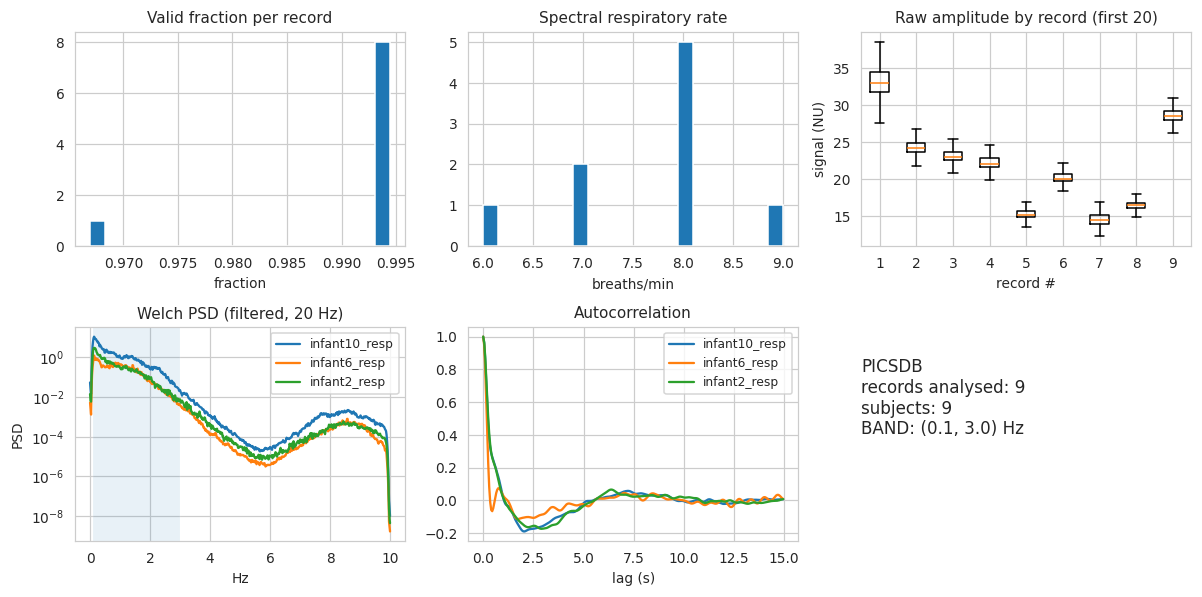

In [12]:
# ---- dataset summary, distributions, spectra, autocorrelation ----
good = QUAL[QUAL["exclude_reason"] == ""]
SUMMARY = pd.DataFrame([dict(dataset=DATASET, n_records_official=len(RECORDS), n_records_selected=int(INV["selected"].sum()), n_records_analysed=len(good),
                             n_subjects=good["subject"].nunique(), fs_native=sorted(good["fs_native"].unique().tolist()),
                             total_hours=good["duration_s"].sum() / 3600, median_duration_s=good["duration_s"].median(),
                             channel_names=sorted(INV["resp_name"].dropna().unique().tolist()), units=sorted(INV.get("resp_units", pd.Series(dtype=str)).dropna().unique().tolist()),
                             median_rr_bpm=good.get("resp_rate_bpm", pd.Series(dtype=float)).median())])
display(SUMMARY.T); save_table(SUMMARY, "dataset_characteristics", top_level=False)

reps = list(good.sort_values("valid_frac_model", ascending=False)["record"].iloc[[0, len(good) // 2, -1]]) if len(good) >= 3 else list(good["record"])
fig, ax = plt.subplots(2, 3, figsize=(11, 5.5))
ax[0, 0].hist(good["valid_frac_model"], bins=20); ax[0, 0].set(title="Valid fraction per record", xlabel="fraction")
if "resp_rate_bpm" in good: ax[0, 1].hist(good["resp_rate_bpm"].dropna(), bins=20); ax[0, 1].set(title="Spectral respiratory rate", xlabel="breaths/min")
ax[0, 2].boxplot([REC[r]["raw"][~REC[r]["bad"]] for r in good["record"].iloc[:min(len(good), 20)]], showfliers=False)
ax[0, 2].set(title="Raw amplitude by record (first 20)", xlabel="record #", ylabel=f"signal ({'/'.join(SUMMARY['units'][0])})")
for r in reps:   # representative PSD and ACF on the causally filtered, valid signal
    d = REC[r]; v = d["filt"][~d["bad"]]
    if len(v) < 200: continue
    fr, pw = sps.welch(v, fs=FS_MODEL, nperseg=min(len(v), 60 * FS_MODEL)); ax[1, 0].semilogy(fr, pw + 1e-20, label=r)
    ac = pd.Series(v).autocorr; lags = np.arange(0, min(len(v) // 2, 15 * FS_MODEL)); ax[1, 1].plot(lags / FS_MODEL, [ac(l) for l in lags[::2]] if False else [np.corrcoef(v[:-l or None][:len(v)-l], v[l:])[0, 1] if l else 1.0 for l in lags], label=r)
ax[1, 0].set(title="Welch PSD (filtered, 20 Hz)", xlabel="Hz", ylabel="PSD"); ax[1, 0].axvspan(*BAND, alpha=.1); ax[1, 0].legend()
ax[1, 1].set(title="Autocorrelation", xlabel="lag (s)"); ax[1, 1].legend()
ax[1, 2].axis("off"); ax[1, 2].text(0, .5, f"{DATASET}\nrecords analysed: {len(good)}\nsubjects: {good['subject'].nunique()}\nBAND: {BAND} Hz", fontsize=11)
fig.tight_layout(); savefig(fig, "fig02_dataset_statistics", f"{DATASET}: record-level statistics, example spectra and autocorrelation (descriptive EDA, from analysed records).")
EDA_REPS = reps

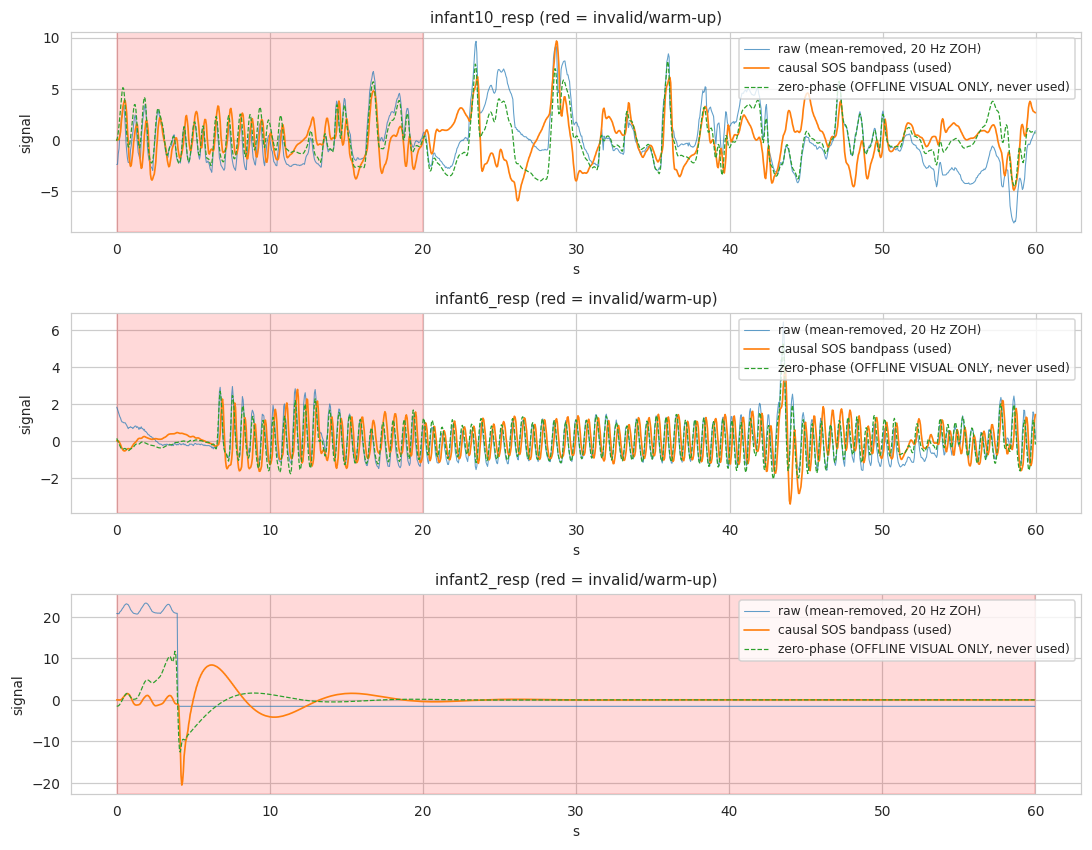

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,mean,std,min,25%,50%,75%,max
peak_hz,9.0,0.070370,0.011111,0.066667,0.066667,0.066667,0.066667,0.100000
power_frac_0.1-3.0Hz,9.0,0.716715,0.088838,0.600427,0.630732,0.734513,0.786783,0.840132
power_frac_0.1-2.0Hz,9.0,0.695304,0.076853,0.590236,0.624490,0.703876,0.761610,0.786727
power_frac_0.2-3.0Hz,9.0,0.540640,0.123042,0.399485,0.405637,0.540128,0.617550,0.699610
power_frac_0.1-5.0Hz,9.0,0.723228,0.089473,0.602396,0.632998,0.741005,0.791968,0.851471


Verified channel(s): ['RESP'] | sampling rates: [500.  50. 250.]
Records per infant: {'infant10_ecg': 1, 'infant10_resp': 1, 'infant1_ecg': 1, 'infant1_resp': 1, 'infant2_ecg': 1, 'infant2_resp': 1, 'infant3_ecg': 1, 'infant3_resp': 1, 'infant4_ecg': 1, 'infant4_resp': 1, 'infant5_ecg': 1, 'infant5_resp': 1, 'infant6_ecg': 1, 'infant6_resp': 1, 'infant7_ecg': 1, 'infant7_resp': 1, 'infant8_ecg': 1, 'infant8_resp': 1, 'infant9_ecg': 1, 'infant9_resp': 1}
Band validation: compare the fraction of spectral power inside each candidate passband (BAND_CHECK above). Neonatal respiratory rates are much higher than adults', so the default band is widened to (0.1, 3.0) -- confirm with the printed peak frequencies; the narrower adult-style band is an ablation.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [13]:
# ---- time-domain EDA: raw vs causal filter vs OFFLINE-ONLY zero-phase reference; artifacts; band validation ----
fig, axs = plt.subplots(len(EDA_REPS), 1, figsize=(10, 2.6 * max(len(EDA_REPS), 1)), squeeze=False)
for a, r in zip(axs[:, 0], EDA_REPS):
    d = REC[r]; n = min(len(d["filt"]), 60 * FS_MODEL); t = np.arange(n) / FS_MODEL
    a.plot(t, d["raw"][:n] - np.nanmean(d["raw"][:n]), lw=.7, label="raw (mean-removed, 20 Hz ZOH)", alpha=.7)
    a.plot(t, d["filt"][:n], lw=1.1, label="causal SOS bandpass (used)")
    sos20 = design_bandpass(BAND, FS_MODEL); a.plot(t, sps.sosfiltfilt(sos20, d["raw"][:n] - np.mean(d["raw"][:n])), lw=.8, ls="--", label="zero-phase (OFFLINE VISUAL ONLY, never used)")
    bad = d["bad"][:n]; s, e = runs(bad)
    for x0, x1 in zip(s, e): a.axvspan(x0 / FS_MODEL, x1 / FS_MODEL, color="red", alpha=.15)
    a.set(title=f"{r} (red = invalid/warm-up)", xlabel="s", ylabel="signal"); a.legend(loc="upper right")
fig.tight_layout(); savefig(fig, "fig03_raw_vs_filtered", f"{DATASET}: raw versus causally filtered respiratory signal; dashed line is an offline-only zero-phase reference.")

# band validation against the observed (training-agnostic, descriptive) spectrum
bv = []
for r, d in REC.items():
    v = d["raw"][~d["bad"]]
    if len(v) < 60 * FS_MODEL: continue
    fr, pw = sps.welch(v - v.mean(), fs=FS_MODEL, nperseg=min(len(v), 60 * FS_MODEL)); tot = pw[(fr > 0.02) & (fr < 5)].sum()
    row = dict(record=r, peak_hz=fr[(fr > 0.05) & (fr < 3)][np.argmax(pw[(fr > 0.05) & (fr < 3)])])
    for b in [BAND] + ALT_BANDS: row[f"power_frac_{b[0]}-{b[1]}Hz"] = pw[(fr >= b[0]) & (fr <= b[1])].sum() / tot
    bv.append(row)
BAND_CHECK = pd.DataFrame(bv); display(BAND_CHECK.describe().T)
if len(BAND_CHECK) and BAND_CHECK["peak_hz"].quantile(.95) > 0.6 * BAND[1]:
    log(f"WARNING: 95th-percentile spectral peak {BAND_CHECK['peak_hz'].quantile(.95):.2f} Hz is close to the upper cutoff {BAND[1]} Hz; consider a wider validated passband.")
save_table(BAND_CHECK, "band_validation", top_level=False)
DATASET_EDA_EXTRA()

# Section E — Signal preprocessing and unit tests
**Pipeline (per record):** forward-fill gaps ≤ `MAX_GAP_S`, flag longer gaps and flat-lines as invalid → causal 4th-order Butterworth band-pass (`sosfilt`, state carried across chunks) at the *native* rate → zero-order-hold resampling to 20 Hz (only the most recent native sample is used, so no future sample is touched; the band-limited signal makes aliasing negligible, checked below) → invalid mask dilated *forward* by the warm-up length → normalisation with **training-subject** mean/std only (fitted per fold in Section F).

**Time alignment.** Model sample *k* occurs at `t = k/20 s` from the segment start and holds native sample `floor(k·fs/20)`.

In [14]:
# ---- unit tests (preprocessing) ----
def test_causal_filter():
    fs = 125.0; sos = design_bandpass(BAND, fs); rng = np.random.RandomState(0); x = rng.randn(5000); x2 = x.copy(); x2[3000:] += 50
    y1 = sps.sosfilt(sos, x); y2 = sps.sosfilt(sos, x2)
    assert np.allclose(y1[:3000], y2[:3000]), "filter output depends on future samples"
    assert sos.ndim == 2 and sos.shape[1] == 6
def test_alias_attenuation():
    for fs in sorted(INV["fs"].dropna().unique()):
        sos = design_bandpass(BAND, fs); w, h = sps.sosfreqz(sos, worN=[FS_MODEL / 2], fs=fs)
        assert 20 * np.log10(abs(h[0]) + 1e-12) < -40, f"insufficient attenuation at {FS_MODEL/2} Hz for fs={fs}"
def test_resample_alignment():
    fs = float(INV["fs"].dropna().iloc[0]); ks = np.arange(0, 2000); nat = np.floor(ks * fs / FS_MODEL + 1e-9)
    lag = ks / FS_MODEL - nat / fs
    assert (lag > -1e-6).all() and (lag < 1 / fs + 1e-6).all(), "ZOH resample used a future sample or is mis-aligned"
def test_flatline_and_gaps():
    x = np.r_[np.random.randn(500), np.ones(400), np.random.randn(500)]
    assert flatline_mask(x, 100., 2.)[600] and not flatline_mask(x, 100., 6.).any()
def test_preprocessing_no_future():
    r = next(iter(REC.values())); row = INV[INV["record"] == r["record"]].iloc[0]
    short = preprocess_record(row, BAND, row["start_s"], min(r["dur_s"], 120.0))
    n = min(len(short["filt"]), len(r["filt"]))
    assert np.allclose(short["filt"][:n - 5 * FS_MODEL], r["filt"][:n - 5 * FS_MODEL], atol=1e-8), "filtered values changed when later data were removed"
for t in [test_causal_filter, test_alias_attenuation, test_resample_alignment, test_flatline_and_gaps, test_preprocessing_no_future]:
    t(); print("PASSED", t.__name__)
mark("unit_tests_preprocessing")

PASSED test_causal_filter
PASSED test_alias_attenuation
PASSED test_resample_alignment
PASSED test_flatline_and_gaps
PASSED test_preprocessing_no_future
[18:01:02] STATUS unit_tests_preprocessing: RUN


# Section F — Subject-level splits and causal windows
Splits are made on **subjects** before any window is extracted. Each fold has train / validation / test subjects (no overlap, asserted). Validation windows are further split *chronologically within each validation record* into `val_sel` (early stopping, hyper-parameter and controller tuning) and `val_cal` (conformal calibration), separated by a gap of `HIST+max horizon` samples.

Window at anchor *i* (last observed sample): input `z[i-99..i]` (5 s @ 20 Hz); targets `z[i+h]`, h ∈ {2,4,6,8,10} steps = {100…500} ms. A window is valid only if **every** sample from `i-99` to `i+10` is valid. Normalisation statistics (mean, std) come from the fold's training records only.

In [15]:
H_STEPS = list(HORIZONS_STEPS); H_MS = [int(round(h * 1000 / FS_MODEL)) for h in H_STEPS]; NH = len(H_STEPS); HMAX = max(H_STEPS); DT = 1.0 / FS_MODEL
HOFF = np.arange(-HIST + 1, 1); HIDX = np.array(H_STEPS)

SUBJ_DF = pd.DataFrame([dict(subject=d["subject"], group=d["group"], record=r) for r, d in REC.items()])
SUBJ_INFO = INV.groupby("subject").agg(age=("age", "first"), sex=("sex", "first"), group=("group", "first")).reset_index()
FOLDS = build_folds(sorted(SUBJ_DF["subject"].unique()), SUBJ_INFO)
manifest = []
for f in FOLDS:
    sets = [set(f["train"]), set(f["val"]), set(f["test"])]
    assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]), "subject overlap between splits"
    for role in ["train", "val", "test"]:
        for s in f[role]: manifest.append(dict(fold=f["fold"], role=role, subject=s, test_group=f["test_group"].get(s, ""),
                                                records="|".join(SUBJ_DF[SUBJ_DF.subject == s]["record"])))
SPLIT = pd.DataFrame(manifest); save_table(SPLIT, "split_manifest"); display(SPLIT.groupby(["fold", "role"]).size().unstack(fill_value=0))

def fit_norm(rec_ids):
    v = np.concatenate([REC[r]["filt"][~REC[r]["bad"]] for r in rec_ids]); return float(v.mean()), float(v.std() + 1e-12)

class WinSet:
    """Index-based windows over one concatenated normalised signal (windows are gathered lazily)."""
    def __init__(self, Z, anc, rec, loc, subj, grp, fold, sd, spans):
        self.Z, self.anc, self.rec, self.loc, self.subj, self.grp, self.fold, self.sd, self.spans = Z, anc, rec, loc, subj, grp, fold, sd, spans
    def __len__(self): return len(self.anc)
    def X(self, sl=slice(None)): return self.Z[self.anc[sl][:, None] + HOFF].astype(np.float32)
    def last(self): return self.Z[self.anc]
    def Y(self): return self.Z[self.anc[:, None] + HIDX]
    def Yh(self, h): return self.Z[self.anc + h]
    def sub(self, mask):
        m = np.asarray(mask); return WinSet(self.Z, self.anc[m], self.rec[m], self.loc[m], self.subj[m], self.grp[m], self.fold[m], self.sd[m], self.spans)

def make_windows(rec_ids, mu, sd, stride, fold_id, test_group=None, loc_range=None):
    Zs, anc_l, rec_l, loc_l, subj_l, grp_l, spans, off = [], [], [], [], [], [], [], 0
    for r in rec_ids:
        d = REC[r]; z = np.where(d["bad"], 0.0, (d["filt"] - mu) / sd).astype(np.float32); n = len(z)
        cum = np.r_[0, np.cumsum(d["bad"])]; a = np.arange(HIST - 1, n - HMAX, stride)
        a = a[(cum[a + HMAX + 1] - cum[a - HIST + 1]) == 0]                      # every sample in [i-99, i+10] valid
        if loc_range is not None: a = a[(a >= loc_range[0] * n) & (a < loc_range[1] * n)] if False else a
        Zs.append(z); anc_l.append(a + off); rec_l += [r] * len(a); loc_l.append(a); subj_l += [d["subject"]] * len(a)
        grp_l += [(test_group or {}).get(d["subject"], d["group"])] * len(a); spans.append((r, off, n)); off += n
    anc = np.concatenate(anc_l) if anc_l else np.zeros(0, int)
    return WinSet(np.concatenate(Zs), anc, np.array(rec_l), np.concatenate(loc_l) if loc_l else np.zeros(0, int), np.array(subj_l), np.array(grp_l),
                  np.full(len(anc), fold_id), np.full(len(anc), sd, dtype=np.float64), spans)

def chrono_split_val(ws: WinSet):
    """First 50% of each validation record -> val_sel, last 50% (after a gap) -> val_cal. Chronology preserved."""
    sel = np.zeros(len(ws), bool); cal = np.zeros(len(ws), bool); gap = HIST + HMAX
    for r in np.unique(ws.rec):
        idx = np.flatnonzero(ws.rec == r); mid = np.median(ws.loc[idx]); sel[idx[ws.loc[idx] < mid - gap / 2]] = True; cal[idx[ws.loc[idx] > mid + gap / 2]] = True
    return ws.sub(sel), ws.sub(cal)

def build_fold_sets(f):
    tr_recs = SUBJ_DF[SUBJ_DF.subject.isin(f["train"])]["record"].tolist(); va_recs = SUBJ_DF[SUBJ_DF.subject.isin(f["val"])]["record"].tolist()
    te_recs = SUBJ_DF[SUBJ_DF.subject.isin(f["test"])]["record"].tolist()
    mu, sd = fit_norm(tr_recs)                                               # TRAIN statistics only
    tr = make_windows(tr_recs, mu, sd, TRAIN_STRIDE, f["fold"]); va = make_windows(va_recs, mu, sd, 1, f["fold"])
    te = make_windows(te_recs, mu, sd, 1, f["fold"], f["test_group"])        # stride 1: needed for continuous control simulation
    vsel, vcal = chrono_split_val(va)
    return dict(train=tr, val_sel=vsel, val_cal=vcal, test=te, mu=mu, sd=sd)

# ---- unit tests: shapes / leakage / overlap ----
def test_windows_no_leakage():
    d0 = next(iter(REC.values())); backup = (d0["filt"].copy(), d0["bad"].copy()); n = 600
    REC["__t"] = dict(filt=np.arange(n, dtype=float), bad=np.zeros(n, bool), subject="s", group="g")
    ws = make_windows(["__t"], 0.0, 1.0, 3, 0); REC.pop("__t")
    X, Y, a = ws.X(), ws.Y(), ws.anc
    assert X.shape == (len(ws), HIST) and Y.shape == (len(ws), NH)
    assert np.allclose(X[:, -1], a) and np.allclose(X[:, 0], a - HIST + 1), "input window not ending at anchor"
    assert np.allclose(Y, a[:, None] + HIDX), "targets misaligned with horizons"
    assert X.max(1).max() <= a.max() and (X.max(1) <= a).all(), "input contains future samples"
def test_invalid_excluded():
    n = 600; bad = np.zeros(n, bool); bad[300:305] = True
    REC["__t"] = dict(filt=np.random.randn(n), bad=bad, subject="s", group="g")
    ws = make_windows(["__t"], 0.0, 1.0, 1, 0); REC.pop("__t")
    for a in ws.loc: assert not bad[a - HIST + 1:a + HMAX + 1].any()
    assert np.isfinite(ws.X()).all() and np.isfinite(ws.Y()).all()
def test_norm_from_train_only():
    f = FOLDS[0]; tr = SUBJ_DF[SUBJ_DF.subject.isin(f["train"])]["record"].tolist(); mu, sd = fit_norm(tr)
    assert set(f["train"]).isdisjoint(f["test"]) and np.isfinite(mu) and sd > 0
for t in [test_windows_no_leakage, test_invalid_excluded, test_norm_from_train_only]: t(); print("PASSED", t.__name__)
FOLD_SETS = {f["fold"]: build_fold_sets(f) for f in FOLDS}
for k, v in FOLD_SETS.items(): print(f"fold {k}: train {len(v['train'])}  val_sel {len(v['val_sel'])}  val_cal {len(v['val_cal'])}  test {len(v['test'])} windows; mu={v['mu']:.4g}, sd={v['sd']:.4g}")
meta = pd.concat([pd.DataFrame(dict(fold=ws.fold, record=ws.rec, subject=ws.subj, anchor_idx=ws.loc, pred_time_s=ws.loc / FS_MODEL, split=name))
                  for fs_ in FOLD_SETS.values() for name, ws in fs_.items() if isinstance(ws, WinSet) and name != "train"]).iloc[::50]
meta.to_csv(OUT / "window_metadata_sample.csv", index=False); _WRITTEN.add(str(OUT / "window_metadata_sample.csv"))
log("Window metadata sample (every 50th window; horizons are the fixed list H_MS) saved.")

role,test,train,val
fold,,,
0,1,7,1
1,1,7,1
2,1,7,1
3,1,7,1
4,1,7,1
5,1,7,1
6,1,7,1
7,1,7,1
8,1,7,1


PASSED test_windows_no_leakage
PASSED test_invalid_excluded
PASSED test_norm_from_train_only


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


fold 0: train 124616  val_sel 35690  val_cal 35690  test 71491 windows; mu=-4.554e-05, sd=0.9749
fold 1: train 125111  val_sel 34700  val_cal 34700  test 71491 windows; mu=0.0002325, sd=1.162
fold 2: train 125111  val_sel 35690  val_cal 35690  test 69511 windows; mu=0.0001161, sd=1.172
fold 3: train 124616  val_sel 35690  val_cal 35690  test 71491 windows; mu=-3.841e-05, sd=1.214
fold 4: train 124616  val_sel 35690  val_cal 35690  test 71491 windows; mu=3.682e-05, sd=1.218
fold 5: train 124616  val_sel 35690  val_cal 35690  test 71491 windows; mu=7.138e-05, sd=1.202
fold 6: train 124616  val_sel 35690  val_cal 35690  test 71491 windows; mu=6.023e-05, sd=1.219
fold 7: train 124616  val_sel 35690  val_cal 35690  test 71491 windows; mu=2.181e-05, sd=1.101
fold 8: train 124616  val_sel 35690  val_cal 35690  test 71491 windows; mu=-0.0001073, sd=0.8418
[18:01:05] Window metadata sample (every 50th window; horizons are the fixed list H_MS) saved.


# Section G — Forecasting models
All models are multi-output (five horizons at once). Metrics applicable to **all** models: MAE, RMSE (point forecast). **Distribution-based** metrics (NLL, PICP, MPIW) apply only to models with a predictive distribution (prob. LSTM, prob. TCN, ensemble, conformal intervals).

| Model | Uncertainty |
|---|---|
| Persistence, Ridge-AR, Kalman | none (point) |
| Probabilistic LSTM / TCN | aleatoric σ (softplus + floor) |
| Deep ensemble (LSTM members) | aleatoric (mean σ²) + epistemic (variance of member means) |
| Split conformal | distribution-free intervals from validation residuals |

**Kalman baseline.** State `[position, velocity]`, constant-velocity model, process-noise `q`, measurement-noise `r` on the (normalised) signal; steady-state gain from the discrete algebraic Riccati equation. *Filtered state* at anchor *i* uses samples ≤ *i*; the *h-step predicted state* is `pos + vel·h·dt`. `(q, r)` are grid-selected on `val_sel`.

In [16]:
class LSTMNet(nn.Module):
    def __init__(s, hidden, layers, prob=True):
        super().__init__(); s.prob = prob; s.lstm = nn.LSTM(1, hidden, layers, batch_first=True); s.head = nn.Linear(hidden, NH * (2 if prob else 1))
    def forward(s, x):
        o = s.head(s.lstm(x)[0][:, -1]); mu = x[:, -1, :] + o[:, :NH]                     # predict increments from last observation
        sg = F.softplus(o[:, NH:]) + SIGMA_MIN if s.prob else None                        # positive, bounded away from 0
        return mu, sg
class CausalBlock(nn.Module):
    def __init__(s, cin, cout, k, d, p):
        super().__init__(); s.pad = (k - 1) * d; s.c1 = nn.Conv1d(cin, cout, k, dilation=d); s.c2 = nn.Conv1d(cout, cout, k, dilation=d)
        s.res = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity(); s.dp = nn.Dropout(p)
    def forward(s, x):
        y = s.dp(F.relu(s.c1(F.pad(x, (s.pad, 0))))); y = s.dp(F.relu(s.c2(F.pad(y, (s.pad, 0))))); return F.relu(y + s.res(x))   # left-padding only: causal
class TCNNet(nn.Module):
    def __init__(s, ch, prob=True, dil=(1, 2, 4, 8, 16, 32), k=3, p=0.1):
        super().__init__(); s.prob = prob; L = []; c = 1
        for d in dil: L.append(CausalBlock(c, ch, k, d, p)); c = ch
        s.net = nn.Sequential(*L); s.head = nn.Linear(ch, NH * (2 if prob else 1))
    def forward(s, x):
        o = s.head(s.net(x.transpose(1, 2))[:, :, -1]); mu = x[:, -1, :] + o[:, :NH]
        return mu, (F.softplus(o[:, NH:]) + SIGMA_MIN if s.prob else None)
def n_params(m): return int(sum(p.numel() for p in m.parameters()))
def gauss_nll_loss(mu, sg, y): return (0.5 * torch.log(2 * math.pi * sg ** 2) + 0.5 * ((y - mu) / sg) ** 2).mean()

def train_nn(model, Xtr, Ytr, Xva, Yva, prob, name, seed):
    """Adam + ReduceLROnPlateau + early stopping + best-checkpoint on validation loss (val_sel only)."""
    set_seed(seed); model.to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    g = torch.Generator().manual_seed(seed)
    Xt = torch.from_numpy(Xtr)[:, :, None].to(DEVICE); Yt = torch.from_numpy(Ytr.astype(np.float32)).to(DEVICE)   # whole train set on the device: no DataLoader overhead
    Xv, Yv = torch.from_numpy(Xva)[:, :, None].to(DEVICE), torch.from_numpy(Yva.astype(np.float32)).to(DEVICE)
    def vloss():
        model.eval(); tot = 0.0
        with torch.no_grad():
            for a in range(0, len(Xv), 8192):
                mu, sg = model(Xv[a:a + 8192]); y = Yv[a:a + 8192]
                tot += (gauss_nll_loss(mu, sg, y) if prob else F.mse_loss(mu, y)).item() * len(y)
        return tot / len(Xv)
    ck = OUT / "models" / f"{name}.pt"; best, bad, hist, t0 = np.inf, 0, [], time.time()
    for ep in range(EPOCHS):
        model.train(); tl, nb = 0.0, 0
        perm = torch.randperm(len(Xt), generator=g).to(DEVICE)
        for b0 in range(0, len(perm), BATCH):
            ib = perm[b0:b0 + BATCH]; xb, yb = Xt[ib], Yt[ib]; opt.zero_grad(); mu, sg = model(xb)
            loss = gauss_nll_loss(mu, sg, yb) if prob else F.mse_loss(mu, yb)
            if not torch.isfinite(loss): raise FloatingPointError(f"{name}: non-finite loss at epoch {ep}")
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tl += loss.item(); nb += 1
        vl = vloss(); sched.step(vl); hist.append(dict(epoch=ep, train_loss=tl / nb, val_loss=vl, lr=opt.param_groups[0]["lr"]))
        if vl < best - 1e-5: best, bad = vl, 0; torch.save(model.state_dict(), ck)
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(torch.load(ck, map_location=DEVICE)); model.eval()
    return pd.DataFrame(hist), time.time() - t0

def predict_nn(model, ws, bs=8192):
    model.eval(); mus, sgs = [], []
    with torch.no_grad():
        for a in range(0, len(ws), bs):
            mu, sg = model(torch.from_numpy(ws.X(slice(a, a + bs)))[:, :, None].to(DEVICE)); mus.append(mu.cpu().numpy()); sgs.append(sg.cpu().numpy() if sg is not None else None)
    return np.concatenate(mus), (np.concatenate(sgs) if sgs and sgs[0] is not None else None)

def kalman_cv(z, q, r, dt=DT):
    """Steady-state constant-velocity Kalman filter. Returns FILTERED position/velocity at every sample (uses samples <= k only)."""
    Fm = np.array([[1, dt], [0, 1.]]); Hm = np.array([[1., 0.]]); Q = q * np.array([[dt ** 3 / 3, dt ** 2 / 2], [dt ** 2 / 2, dt]])
    P = solve_discrete_are(Fm.T, Hm.T, Q, np.array([[r]])); K = (P @ Hm.T / (Hm @ P @ Hm.T + r)).ravel(); k0, k1 = float(K[0]), float(K[1])
    # steady-state filter is LTI: x[k|k] = (I-KH)F x[k-1|k-1] + K z[k]  -> vectorised with lfilter (identical to the per-sample recursion, ~100x faster)
    A = (np.eye(2) - np.outer([k0, k1], Hm[0])) @ Fm; Kc = np.array([[k0], [k1]])
    num, den = sps.ss2tf(A, Kc, A, Kc)                        # w[k]=x[k-1|k-1]: x[k|k] = A w[k] + K z[k]
    return sps.lfilter(num[0], den, z), sps.lfilter(num[1], den, z)
def kalman_forecast(ws, q, r):
    out = np.zeros((len(ws), NH))
    for rid, off, n in ws.spans:
        sel = np.flatnonzero(ws.rec == rid)
        if len(sel) == 0: continue
        pos, vel = kalman_cv(ws.Z[off:off + n].astype(float), q, r); a = ws.anc[sel] - off
        out[sel] = pos[a][:, None] + vel[a][:, None] * HIDX[None] * DT                  # predicted state = filtered + h*dt*velocity
    return out

def point_scores(y, mu): e = y - mu; return dict(mae=np.abs(e).mean(0), rmse=np.sqrt((e ** 2).mean(0)))

[18:01:05] === fitting fold 0 (7 train / 1 val / 1 test subjects)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=9.84516e-10): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.05435e-08): result may not be accurate.
  return 

[18:06:35] fold 0 info: {'ridge_alpha': 100, 'kalman_q_r': (100, 0.001), 'latency_ms_per_window': {'lstm_prob': 0.3017306327819824, 'tcn_prob': 1.8160271644592285}}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/tmp/ipykernel_23/2072376356.py:68: ResourceWarning: unclosed file <_io.BufferedWriter name='/kaggle/working/results/picsdb/full_20261010_172301/models/fit_cache_fold0.pkl'>
  pickle.dump({k: v for k, v in FIT[f["fold"]].items() if k != "sets"}, open(cache, "wb"))


[18:06:36] === fitting fold 1 (7 train / 1 val / 1 test subjects)


...

[19:19:21] === fitting fold 8 (7 train / 1 val / 1 test subjects)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

[19:25:18] fold 8 info: {'ridge_alpha': 0.001, 'kalman_q_r': (0.01, 1), 'latency_ms_per_window': {'lstm_prob': 0.31710386276245117, 'tcn_prob': 1.8163156509399414}}
[19:25:19] STATUS forecasting_models: RUN


/tmp/ipykernel_23/2072376356.py:68: ResourceWarning: unclosed file <_io.BufferedWriter name='/kaggle/working/results/picsdb/full_20261010_172301/models/fit_cache_fold8.pkl'>
  pickle.dump({k: v for k, v in FIT[f["fold"]].items() if k != "sets"}, open(cache, "wb"))
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,params,train_time_s,epochs,fold
0,lstm_member0,17802,8.637031,7,0
1,lstm_member1,17802,7.344359,7,0
2,lstm_member2,17802,8.499251,8,0
3,lstm_member3,17802,8.579245,8,0
4,lstm_member4,17802,8.654043,8,0
...,...,...,...,...,...
2,lstm_member2,17802,25.682304,22,8
3,lstm_member3,17802,17.443776,15,8
4,lstm_member4,17802,20.952134,18,8
5,tcn_prob,34666,109.324341,13,8


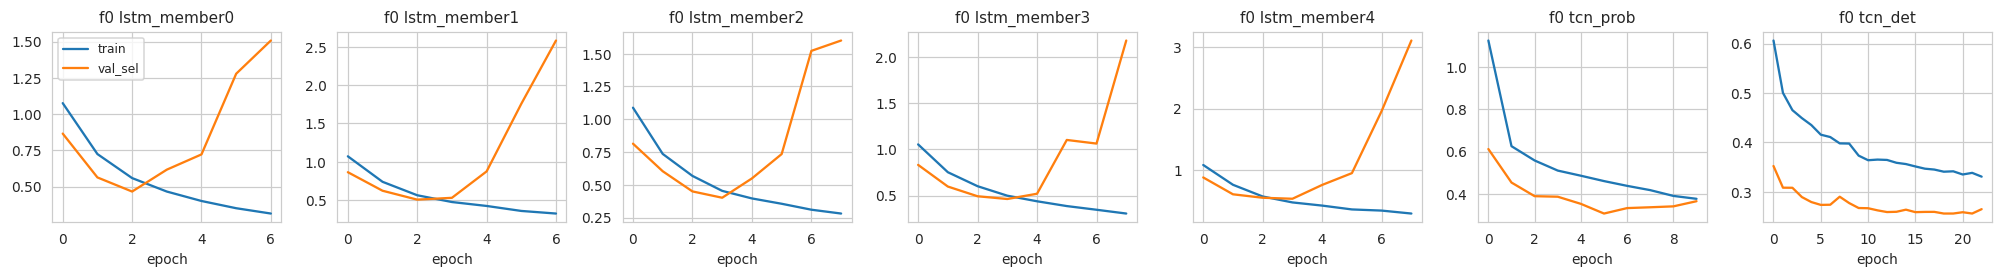

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


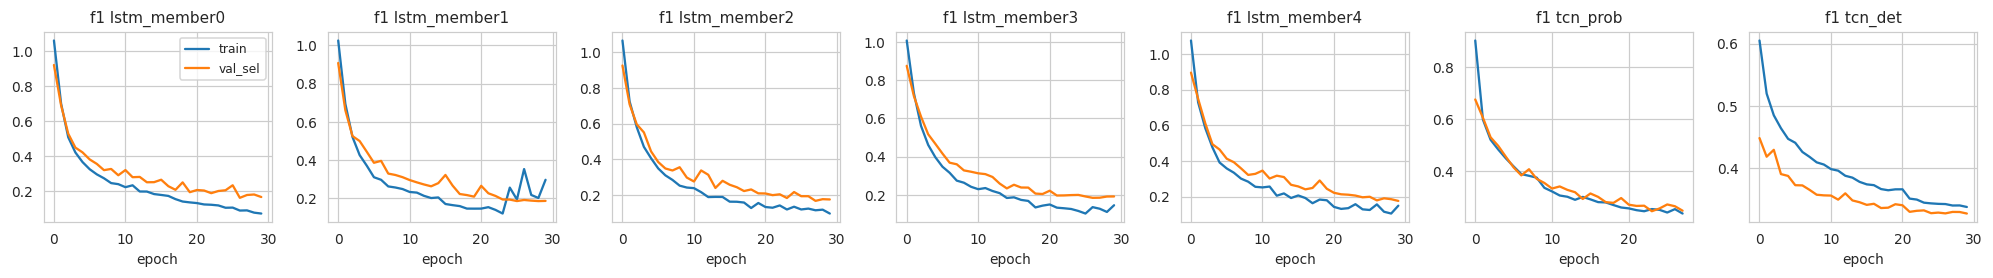

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


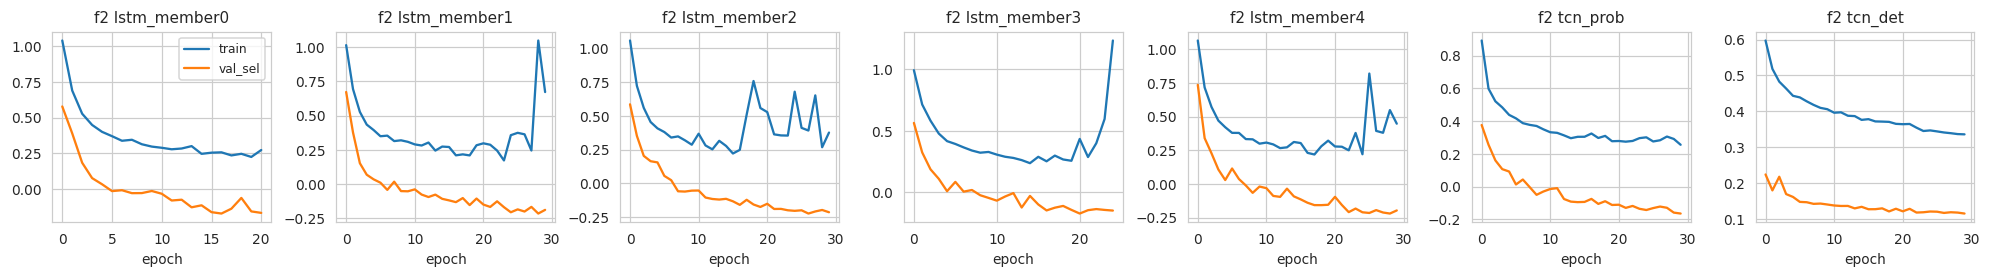

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


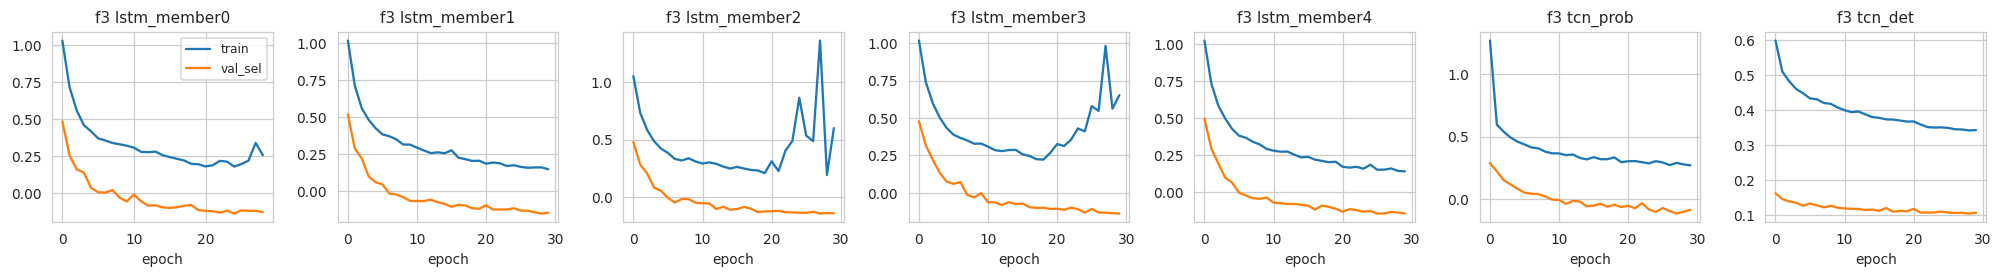

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


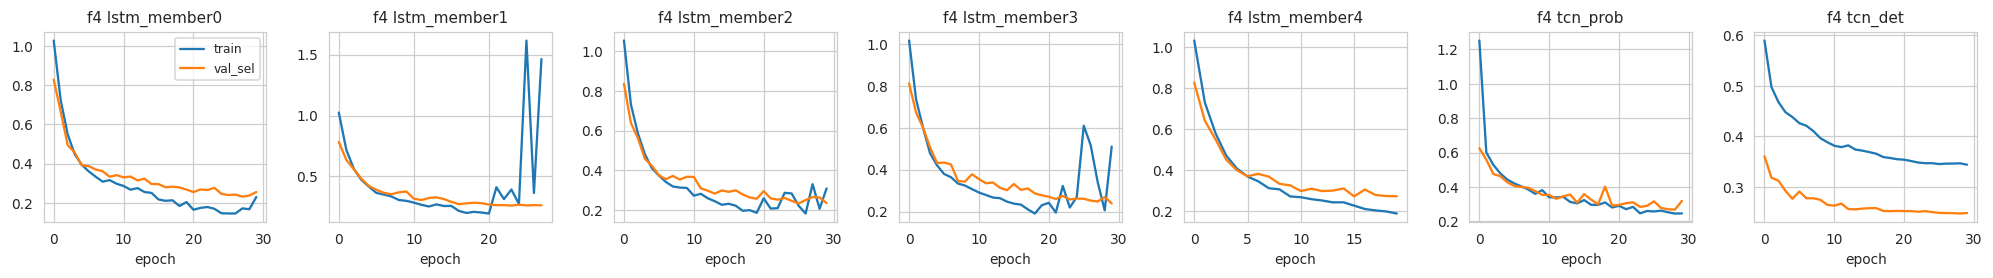

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


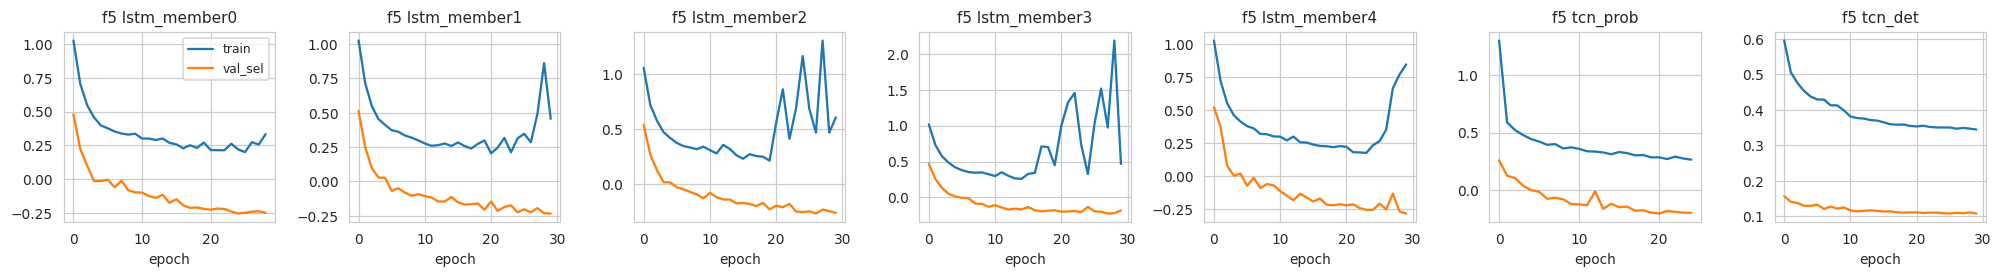

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


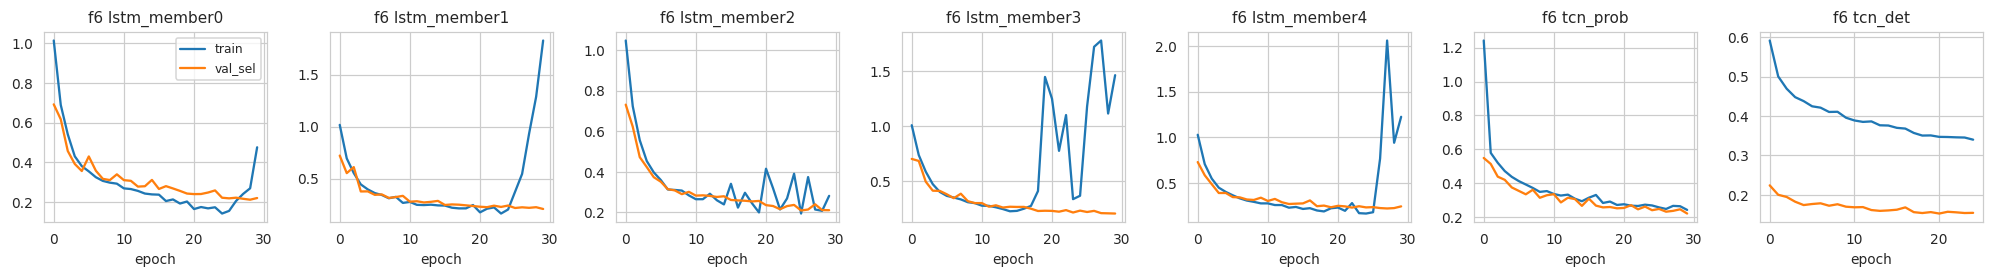

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


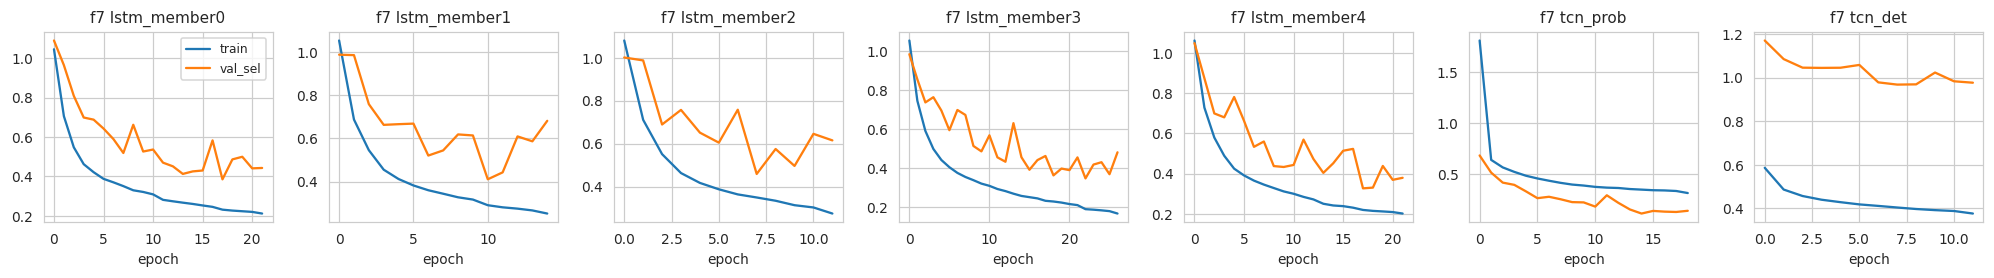

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


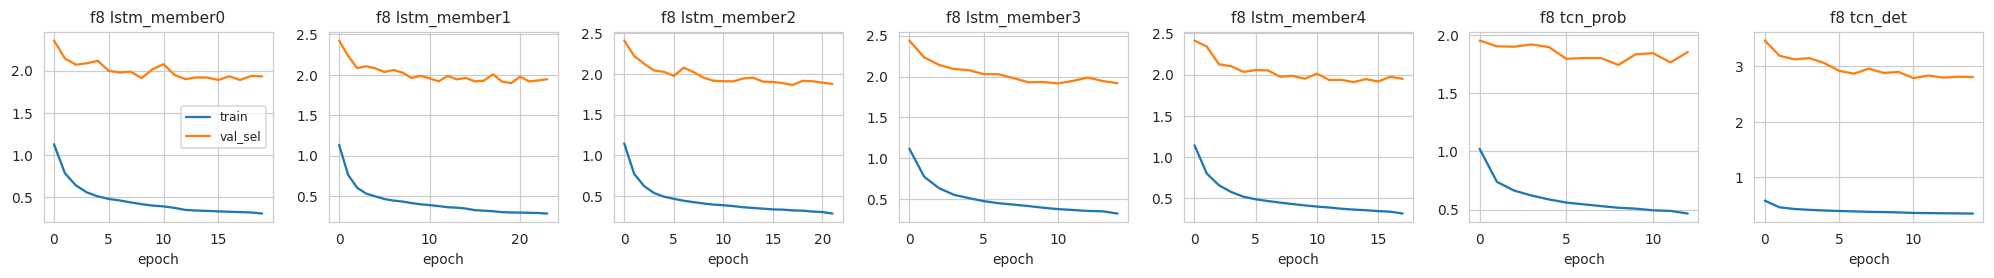

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:
def conformal_q(scores, alpha):
    n = len(scores); k = int(math.ceil((n + 1) * (1 - alpha)))
    return np.inf if k > n else float(np.sort(scores)[k - 1])

def fit_fold(f):
    """Train/tune everything on TRAIN + val_sel (+val_cal for conformal) and predict val_sel / val_cal / test."""
    S = FOLD_SETS[f["fold"]]; tr, vs, vc, te = S["train"], S["val_sel"], S["val_cal"], S["test"]
    assert len(tr) > 0 and len(vs) > 0 and len(vc) > 0 and len(te) > 0, f"fold {f['fold']}: an empty split; check exclusions/limits"
    Xtr, Ytr = tr.X(), tr.Y(); sub = np.arange(0, len(vs), VAL_SUB); Xva, Yva = vs.X(slice(None))[sub], vs.Y()[sub]
    info, hist = {}, {}; P = {"val_sel": {}, "val_cal": {}, "test": {}}; ws_map = dict(val_sel=vs, val_cal=vc, test=te)
    def put(name, fn):
        for k, w in ws_map.items(): mu, sg = fn(w); P[k][name] = dict(mu=mu, sigma=sg)
    put("persistence", lambda w: (np.repeat(w.last()[:, None], NH, 1), None))
    best = (np.inf, None)                                                           # ridge-AR: alpha on val_sel only
    for a in RIDGE_ALPHAS:
        m = Ridge(alpha=a).fit(Xtr, Ytr); e = np.abs(m.predict(Xva) - Yva).mean()
        if e < best[0]: best = (e, a)
    ridge = Ridge(alpha=best[1]).fit(Xtr, Ytr); info["ridge_alpha"] = best[1]; put("ridge", lambda w: (ridge.predict(w.X()), None))
    bk = (np.inf, None)                                                             # Kalman (q, r) on val_sel only
    for q in KF_Q:
        for r in KF_R:
            e = np.abs(kalman_forecast(vs, q, r) - vs.Y()).mean()
            if e < bk[0]: bk = (e, (q, r))
    info["kalman_q_r"] = bk[1]; put("kalman", lambda w: (kalman_forecast(w, *bk[1]), None))
    # probabilistic LSTM members (member 0 == "lstm_prob"), deep ensemble
    members, pinfo = [], []
    for m_i in range(ENS_SIZE):
        net = LSTMNet(HIDDEN, LAYERS, True); h, tt = train_nn(net, Xtr, Ytr, Xva, Yva, True, f"f{f['fold']}_lstm_member{m_i}", SEED + 100 * m_i)
        members.append(net); hist[f"lstm_member{m_i}"] = h; pinfo.append(dict(model=f"lstm_member{m_i}", params=n_params(net), train_time_s=tt, epochs=len(h)))
    outs = {k: [predict_nn(m, w) for m in members] for k, w in ws_map.items()}
    for k in ws_map:
        mus = np.stack([o[0] for o in outs[k]]); sgs = np.stack([o[1] for o in outs[k]])
        P[k]["lstm_prob"] = dict(mu=mus[0], sigma=sgs[0])
        ale = (sgs ** 2).mean(0); epi = mus.var(0)                                 # law of total variance for a uniform mixture of Gaussians
        P[k]["ensemble"] = dict(mu=mus.mean(0), sigma=np.sqrt(ale + epi), ale=np.sqrt(ale), epi=np.sqrt(epi))
    tcn_p = TCNNet(TCN_CH, True); h, tt = train_nn(tcn_p, Xtr, Ytr, Xva, Yva, True, f"f{f['fold']}_tcn_prob", SEED + 7); hist["tcn_prob"] = h
    pinfo.append(dict(model="tcn_prob", params=n_params(tcn_p), train_time_s=tt, epochs=len(h)))
    tcn_d = TCNNet(TCN_CH, False); h, tt = train_nn(tcn_d, Xtr, Ytr, Xva, Yva, False, f"f{f['fold']}_tcn_det", SEED + 8); hist["tcn_det"] = h
    pinfo.append(dict(model="tcn_det", params=n_params(tcn_d), train_time_s=tt, epochs=len(h)))
    put("tcn_prob", lambda w: predict_nn(tcn_p, w)); put("tcn_det", lambda w: predict_nn(tcn_d, w))
    # latency benchmark (batch of 1, CPU/GPU as configured)
    x1 = torch.from_numpy(te.X(slice(0, 1)))[:, :, None].to(DEVICE); lat = {}
    for nm, net in [("lstm_prob", members[0]), ("tcn_prob", tcn_p)]:
        with torch.no_grad():
            for _ in range(5): net(x1)
            t0 = time.time(); [net(x1) for _ in range(100)]; lat[nm] = (time.time() - t0) / 100 * 1e3
    info["latency_ms_per_window"] = lat
    # split conformal on val_cal (separate from training and from val_sel used for early stopping)
    CONF = {}
    for nm in ["ridge", "lstm_prob", "tcn_prob", "ensemble", "persistence"]:
        yc = vc.Y(); mu_c = P["val_cal"][nm]["mu"]; res = np.abs(yc - mu_c); sg_c = P["val_cal"][nm]["sigma"]
        for alpha in [0.10, 0.05]:
            q_abs = np.array([conformal_q(res[:, j], alpha) for j in range(NH)]); CONF[(nm, "abs", alpha)] = q_abs
            if sg_c is not None: CONF[(nm, "norm", alpha)] = np.array([conformal_q(res[:, j] / sg_c[:, j], alpha) for j in range(NH)])
    for k in ws_map:
        for (nm, kind, alpha), q in CONF.items():
            mu_, sg_ = P[k][nm]["mu"], P[k][nm]["sigma"]; half = q[None] if kind == "abs" else q[None] * sg_
            P[k][nm][f"conf_{kind}_{int(alpha*100)}"] = (mu_ - half, mu_ + half)
    return dict(P=P, info=info, hist=hist, pinfo=pd.DataFrame(pinfo), sets=S)

FIT = {}
for f in FOLDS:
    cache = OUT / "models" / f"fit_cache_fold{f['fold']}.pkl"            # per-fold cache: a crashed/timed-out run resumes (set RESUME_RUN) instead of retraining
    if USE_CACHE and cache.exists():
        FIT[f["fold"]] = pickle.load(open(cache, "rb")); FIT[f["fold"]]["sets"] = FOLD_SETS[f["fold"]]; log(f"fold {f['fold']}: loaded cached fit {cache.name}"); continue
    log(f"=== fitting fold {f['fold']} ({len(f['train'])} train / {len(f['val'])} val / {len(f['test'])} test subjects)"); FIT[f["fold"]] = fit_fold(f)
    log(f"fold {f['fold']} info: {FIT[f['fold']]['info']}")
    pickle.dump({k: v for k, v in FIT[f["fold"]].items() if k != "sets"}, open(cache, "wb"))
mark("forecasting_models")
display(pd.concat([v["pinfo"].assign(fold=k) for k, v in FIT.items()]))
for k, v in FIT.items():
    fig, axs = plt.subplots(1, len(v["hist"]), figsize=(2.6 * len(v["hist"]), 2.6), squeeze=False)
    for a, (nm, h) in zip(axs[0], v["hist"].items()): a.plot(h["train_loss"], label="train"); a.plot(h["val_loss"], label="val_sel"); a.set(title=f"f{k} {nm}", xlabel="epoch")
    axs[0, 0].legend(); fig.tight_layout(); savefig(fig, f"fig_training_curves_fold{k}", f"Training/validation loss curves (fold {k}).")

In [18]:
# ---- merge test windows across folds into one table; subject-level forecast + uncertainty metrics ----
TEST = dict(rec=np.concatenate([FIT[k]["sets"]["test"].rec for k in FIT]), subj=np.concatenate([FIT[k]["sets"]["test"].subj for k in FIT]),
            grp=np.concatenate([FIT[k]["sets"]["test"].grp for k in FIT]), fold=np.concatenate([FIT[k]["sets"]["test"].fold for k in FIT]),
            loc=np.concatenate([FIT[k]["sets"]["test"].loc for k in FIT]), sd=np.concatenate([FIT[k]["sets"]["test"].sd for k in FIT]),
            Y=np.concatenate([FIT[k]["sets"]["test"].Y() for k in FIT]), last=np.concatenate([FIT[k]["sets"]["test"].last() for k in FIT]))
MODELS = list(FIT[FOLDS[0]["fold"]]["P"]["test"].keys()); NTEST = len(TEST["subj"])
def merged(name, key):
    arrs = [FIT[k]["P"]["test"][name].get(key) for k in FIT]
    if arrs[0] is None: return None
    if isinstance(arrs[0], tuple): return (np.concatenate([a[0] for a in arrs]), np.concatenate([a[1] for a in arrs]))
    return np.concatenate(arrs)
PT = {m: {k: merged(m, k) for k in FIT[FOLDS[0]["fold"]]["P"]["test"][m].keys()} for m in MODELS}

def gnll(y, mu, sg): return 0.5 * np.log(2 * np.pi * sg ** 2) + 0.5 * ((y - mu) / sg) ** 2
Z90, Z95 = sstats.norm.ppf(0.95), sstats.norm.ppf(0.975)
def subject_metrics(model, key=None):
    P_ = PT[model]; mu, sg = P_["mu"], P_["sigma"]; rows = []
    for s in np.unique(TEST["subj"]):
        m = TEST["subj"] == s; y = TEST["Y"][m]; e = y - mu[m]; sd = TEST["sd"][m][:, None]; g = TEST["grp"][m][0]
        for j in range(NH):
            r = dict(model=model, subject=s, group=g, horizon_ms=H_MS[j], n_windows=int(m.sum()), mae=np.abs(e[:, j]).mean(), rmse=np.sqrt((e[:, j] ** 2).mean()),
                     mae_units=(np.abs(e[:, j]) * sd[:, 0]).mean(), rmse_units=np.sqrt(((e[:, j] * sd[:, 0]) ** 2).mean()))
            if sg is not None:
                s_ = sg[m][:, j]; r.update(nll=gnll(y[:, j], mu[m][:, j], s_).mean(), mean_sigma=s_.mean(), mean_sigma_units=(s_ * sd[:, 0]).mean(),
                                          picp90=(np.abs(e[:, j]) <= Z90 * s_).mean(), picp95=(np.abs(e[:, j]) <= Z95 * s_).mean(), mpiw95=(2 * Z95 * s_).mean(),
                                          spearman_sigma_abs_err=sstats.spearmanr(s_, np.abs(e[:, j]))[0] if m.sum() > 10 else np.nan)
                for kind in ["abs", "norm"]:
                    for a in [10, 5]:
                        ck = f"conf_{kind}_{a}"
                        if ck in P_ and P_[ck] is not None:
                            lo, hi = P_[ck][0][m][:, j], P_[ck][1][m][:, j]; r[f"{ck}_picp"] = ((y[:, j] >= lo) & (y[:, j] <= hi)).mean(); r[f"{ck}_mpiw"] = (hi - lo).mean()
            else:
                for a in [10, 5]:
                    ck = f"conf_abs_{a}"
                    if ck in P_ and P_[ck] is not None:
                        lo, hi = P_[ck][0][m][:, j], P_[ck][1][m][:, j]; r[f"{ck}_picp"] = ((y[:, j] >= lo) & (y[:, j] <= hi)).mean(); r[f"{ck}_mpiw"] = (hi - lo).mean()
            rows.append(r)
    return rows
FM = pd.DataFrame([r for m in MODELS for r in subject_metrics(m)])

def boot_ci(vals, B=None, seed=0, fn=np.mean):
    """Subject-level percentile bootstrap CI of fn over per-subject values."""
    v = np.asarray([x for x in vals if np.isfinite(x)]); B = B or N_BOOT
    if len(v) < 2: return (np.nan, np.nan)
    rng = np.random.RandomState(seed); b = [fn(v[rng.randint(0, len(v), len(v))]) for _ in range(B)]; return tuple(np.percentile(b, [2.5, 97.5]))
def summarize(df, by, cols):
    rows = []
    for k, g in df.groupby(by):
        k = k if isinstance(k, tuple) else (k,); r = dict(zip(by, k)); r["n_subjects"] = g["subject"].nunique()
        for c in cols:
            if c in g and g[c].notna().any(): ci = boot_ci(g[c].values); r[c] = g[c].mean(); r[c + "_lo"], r[c + "_hi"] = ci
        rows.append(r)
    return pd.DataFrame(rows)
FORECAST_TABLE = summarize(FM, ["model", "horizon_ms"], ["mae", "rmse", "mae_units", "rmse_units"]); save_table(FORECAST_TABLE, "forecast_metrics"); display(FORECAST_TABLE.round(4).head(30))
mark("forecast_evaluation")

,model,horizon_ms,n_subjects,mae,mae_lo,mae_hi,rmse,rmse_lo,rmse_hi,mae_units,mae_units_lo,mae_units_hi,rmse_units,rmse_units_lo,rmse_units_hi
0,ensemble,100,9,0.1736,0.1054,0.2660,0.3363,0.1846,0.5280,0.1873,0.1173,0.2759,0.3491,0.2184,0.5125
1,ensemble,200,9,0.3943,0.2658,0.5656,0.6758,0.4336,0.9763,0.4279,0.2981,0.5959,0.7146,0.5072,0.9632
2,ensemble,300,9,0.5014,0.3556,0.7222,0.8014,0.5280,1.1553,0.5414,0.4085,0.7353,0.8479,0.6250,1.1333
3,ensemble,400,9,0.5191,0.3621,0.7600,0.8114,0.5210,1.2039,0.5560,0.4269,0.7691,0.8533,0.6151,1.1606
4,ensemble,500,9,0.5381,0.3669,0.7937,0.8372,0.5269,1.2573,0.5743,0.4346,0.7955,0.8778,0.6233,1.2015
5,kalman,100,9,0.5915,0.4689,0.7449,0.8473,0.6280,1.1735,0.6465,0.5327,0.7544,0.9109,0.7275,1.1397
6,kalman,200,9,0.7951,0.5993,1.0567,1.1378,0.7937,1.5916,0.8558,0.7054,1.0645,1.2081,0.9419,1.5594
7,kalman,300,9,0.9978,0.6450,1.4758,1.4179,0.8734,2.1386,1.0625,0.7600,1.5119,1.4932,1.0271,2.1415
8,kalman,400,9,1.1592,0.6667,1.8587,1.6405,0.9072,2.6081,1.2261,0.7774,1.8515,1.7188,1.0656,2.6342
9,kalman,500,9,1.2854,0.6734,2.1743,1.8225,0.9347,3.0364,1.3531,0.7825,2.1436,1.9025,1.0925,3.0796


[19:25:47] STATUS forecast_evaluation: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section H — Uncertainty estimation and calibration
* **Aleatoric**: σ of the probabilistic LSTM (data noise as learned). **Epistemic**: spread of ensemble-member means. **Total** variance = mean(σ²ₘ) + Var(μₘ) (law of total variance for the equal-weight Gaussian mixture; reported as the moment-matched Gaussian).
* Intervals: Gaussian (±1.645σ for 90 %, ±1.96σ for 95 %); split-conformal absolute-residual intervals and σ-normalised conformal intervals.
* **Conformal assumptions/limitations**: coverage ≥ 1−α holds for *exchangeable* calibration/test data. Respiratory windows are strongly autocorrelated and test subjects are from a shifted population, so only approximate marginal coverage is expected; we measure rather than assume it.
* **Units**: σ is in normalised units; multiplying by the training standard deviation (`sd`, stored per window) converts to signal units (`*_units` columns). NLL in signal units = NLL_norm + log(sd).

,model,horizon_ms,n_subjects,nll,nll_lo,nll_hi,picp90,picp90_lo,picp90_hi,picp95,...,conf_norm_10_picp_hi,conf_norm_10_mpiw,conf_norm_10_mpiw_lo,conf_norm_10_mpiw_hi,conf_norm_5_picp,conf_norm_5_picp_lo,conf_norm_5_picp_hi,conf_norm_5_mpiw,conf_norm_5_mpiw_lo,conf_norm_5_mpiw_hi
0,ensemble,100,9,2.752,-0.431,8.759,0.726,0.589,0.815,0.773,...,0.921,0.740,0.486,1.062,0.934,0.905,0.961,0.968,0.642,1.389
1,ensemble,200,9,1.575,0.352,3.720,0.785,0.679,0.859,0.833,...,0.922,1.681,1.201,2.284,0.935,0.906,0.962,2.228,1.572,3.064
2,ensemble,300,9,1.041,0.594,1.644,0.847,0.774,0.897,0.891,...,0.922,2.115,1.540,2.794,0.939,0.914,0.964,2.751,2.002,3.618
3,ensemble,400,9,0.867,0.603,1.217,0.903,0.879,0.922,0.941,...,0.926,2.117,1.533,2.889,0.944,0.921,0.966,2.679,1.933,3.630
4,ensemble,500,9,0.900,0.618,1.268,0.921,0.898,0.938,0.953,...,0.920,2.149,1.495,2.996,0.943,0.925,0.961,2.704,1.886,3.760
5,lstm_prob,100,9,7.722,0.221,22.314,0.689,0.555,0.776,0.737,...,0.919,0.826,0.525,1.207,0.937,0.909,0.963,1.127,0.706,1.654
6,lstm_prob,200,9,2.803,0.561,6.981,0.760,0.652,0.835,0.809,...,0.919,1.798,1.254,2.479,0.933,0.904,0.960,2.460,1.674,3.466
7,lstm_prob,300,9,1.278,0.686,2.183,0.823,0.747,0.878,0.871,...,0.918,2.200,1.603,2.905,0.937,0.911,0.961,2.898,2.103,3.808
8,lstm_prob,400,9,0.925,0.639,1.304,0.885,0.856,0.909,0.928,...,0.921,2.176,1.565,2.965,0.942,0.919,0.963,2.751,1.984,3.703
9,lstm_prob,500,9,0.939,0.635,1.334,0.906,0.880,0.926,0.943,...,0.916,2.182,1.521,3.056,0.940,0.920,0.958,2.738,1.903,3.811


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


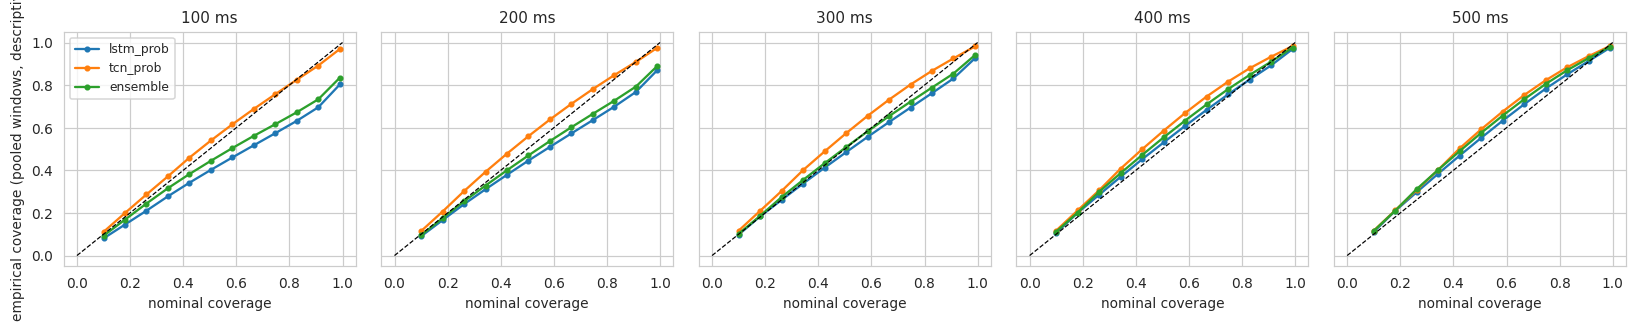

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/tmp/ipykernel_23/1588287104.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  rho = FM[FM.model == "ensemble"].pivot(index="subject", columns="horizon_ms", values="spearman_sigma_abs_err"); axs[2].boxplot([rho[c].dropna() for c in rho.columns], labels=rho.columns); axs[2].axhline(0, c="k", lw=.5)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.dateti

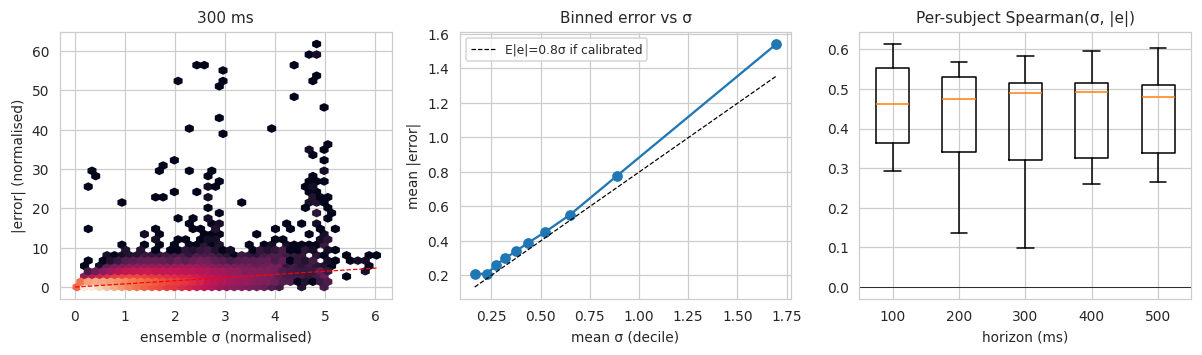

[19:25:55] STATUS uncertainty_calibration: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [19]:
UM_rows = FM[FM["model"].isin(["lstm_prob", "tcn_prob", "ensemble"])]
cols = ["nll", "picp90", "picp95", "mpiw95", "mean_sigma", "mean_sigma_units", "spearman_sigma_abs_err"] + [c for c in FM.columns if c.startswith("conf_")]
UNC_TABLE = summarize(FM[FM["model"].isin(["lstm_prob", "tcn_prob", "ensemble", "ridge", "persistence"])], ["model", "horizon_ms"], [c for c in cols if c in FM.columns])
save_table(UNC_TABLE, "uncertainty_metrics"); display(UNC_TABLE.round(3).head(30))
# coverage (reliability) curves
LEVELS = np.linspace(0.1, 0.99, 12)
def coverage_curve(model, j):
    mu, sg = PT[model]["mu"][:, j], PT[model]["sigma"][:, j]; e = np.abs(TEST["Y"][:, j] - mu); return np.array([(e <= sstats.norm.ppf(0.5 + l / 2) * sg).mean() for l in LEVELS])
fig, axs = plt.subplots(1, NH, figsize=(3 * NH, 3), sharey=True)
for j, a in enumerate(axs):
    for m in ["lstm_prob", "tcn_prob", "ensemble"]: a.plot(LEVELS, coverage_curve(m, j), marker="o", ms=3, label=m)
    a.plot([0, 1], [0, 1], "k--", lw=.8); a.set(title=f"{H_MS[j]} ms", xlabel="nominal coverage")
axs[0].set_ylabel("empirical coverage (pooled windows, descriptive)"); axs[0].legend(); fig.tight_layout()
savefig(fig, "fig07_calibration_coverage", "Empirical versus nominal central-interval coverage per forecast horizon (pooled test windows; subject-level CIs are in the tables).")
# error vs uncertainty
fig, axs = plt.subplots(1, 3, figsize=(11, 3.3)); j = NH // 2
sg = PT["ensemble"]["sigma"][:, j]; er = np.abs(TEST["Y"][:, j] - PT["ensemble"]["mu"][:, j]); hb = axs[0].hexbin(sg, er, gridsize=40, bins="log", mincnt=1)
axs[0].set(xlabel="ensemble σ (normalised)", ylabel="|error| (normalised)", title=f"{H_MS[j]} ms"); axs[0].plot([0, sg.max()], [0, 0.8 * sg.max()], "r--", lw=.8)
q = pd.qcut(sg, 10, duplicates="drop"); g = pd.DataFrame(dict(s=sg, e=er)).groupby(q, observed=True).mean(); axs[1].plot(g["s"], g["e"], "o-"); axs[1].plot(g["s"], 0.798 * g["s"], "k--", lw=.8, label="E|e|=0.8σ if calibrated")
axs[1].set(xlabel="mean σ (decile)", ylabel="mean |error|", title="Binned error vs σ"); axs[1].legend()
rho = FM[FM.model == "ensemble"].pivot(index="subject", columns="horizon_ms", values="spearman_sigma_abs_err"); axs[2].boxplot([rho[c].dropna() for c in rho.columns], labels=rho.columns); axs[2].axhline(0, c="k", lw=.5)
axs[2].set(title="Per-subject Spearman(σ, |e|)", xlabel="horizon (ms)"); fig.tight_layout()
savefig(fig, "fig08_uncertainty_vs_error", "Predicted uncertainty versus absolute forecast error (ensemble). Subject-level Spearman correlations test whether σ tracks error.")
mark("uncertainty_calibration")

# Section I — Distribution-shift experiment
**Leave-one-infant-out (LOIO).** For each fold one infant is the test subject, the next infant (cyclic) is the validation subject and the rest are training. Fold-level normalisation/tuning use only that fold's training/validation infants. This tests generalisation to held-out infants; with so few infants, confidence intervals are wide. Optional cross-dataset transfer from BIDMC/Fantasia is **NOT RUN** unless explicitly added (it would require documenting preprocessing and normalisation differences).

Reported per evaluation group: subject-level error, mean σ, interval coverage and calibration deterioration (PICP − nominal). Whether σ *tracks* deterioration is tested by comparing group-level changes in MAE and σ and by within-group σ–|error| correlation; no direction is assumed. Normalised amplitudes are used throughout; raw amplitudes are never compared across datasets.

,model,group,horizon_ms,n_subjects,mae,mae_lo,mae_hi,rmse,rmse_lo,rmse_hi,...,spearman_sigma_abs_err,spearman_sigma_abs_err_lo,spearman_sigma_abs_err_hi,conf_norm_10_picp,conf_norm_10_picp_lo,conf_norm_10_picp_hi,conf_abs_10_picp,conf_abs_10_picp_lo,conf_abs_10_picp_hi,picp95_minus_nominal
0,ensemble,held_out_infant,100,9,0.174,0.105,0.266,0.336,0.185,0.528,...,0.463,0.398,0.528,0.881,0.845,0.921,0.857,0.755,0.938,-0.177
1,ensemble,held_out_infant,200,9,0.394,0.266,0.566,0.676,0.434,0.976,...,0.424,0.331,0.509,0.880,0.842,0.922,0.858,0.757,0.938,-0.117
2,ensemble,held_out_infant,300,9,0.501,0.356,0.722,0.801,0.528,1.155,...,0.406,0.301,0.497,0.886,0.852,0.922,0.864,0.768,0.940,-0.059
3,ensemble,held_out_infant,400,9,0.519,0.362,0.760,0.811,0.521,1.204,...,0.428,0.355,0.501,0.895,0.861,0.926,0.863,0.774,0.935,-0.009
4,ensemble,held_out_infant,500,9,0.538,0.367,0.794,0.837,0.527,1.257,...,0.433,0.365,0.502,0.892,0.865,0.920,0.859,0.773,0.934,0.003


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[19:25:57] STATUS distribution_shift: NOT RUN: only one evaluation group present ([np.str_('held_out_infant')]); see held-out-subject results above


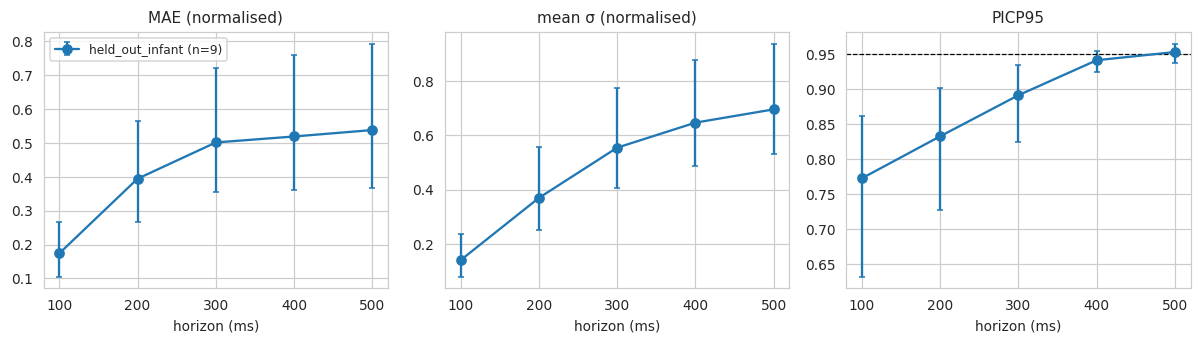

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [20]:
SHIFT = FM[FM["model"].isin(["ensemble", "lstm_prob", "persistence", "ridge"])].copy()
SHIFT_TABLE = summarize(SHIFT, ["model", "group", "horizon_ms"], ["mae", "rmse", "nll", "mean_sigma", "picp90", "picp95", "spearman_sigma_abs_err", "conf_norm_10_picp", "conf_abs_10_picp"])
SHIFT_TABLE["picp95_minus_nominal"] = SHIFT_TABLE.get("picp95", np.nan) - 0.95
save_table(SHIFT_TABLE, "distribution_shift_performance", top_level=False); display(SHIFT_TABLE[SHIFT_TABLE.model == "ensemble"].round(3))
groups = sorted(FM["group"].unique()); SHIFT_TESTS = []
if len(groups) >= 2:
    ref = groups[0]
    for g2 in groups[1:]:
        for j, hm in enumerate(H_MS):
            a = FM[(FM.model == "ensemble") & (FM.group == ref) & (FM.horizon_ms == hm)]; b = FM[(FM.model == "ensemble") & (FM.group == g2) & (FM.horizon_ms == hm)]
            for metric in ["mae", "mean_sigma", "picp95"]:
                if len(a) >= 2 and len(b) >= 2:
                    u = sstats.mannwhitneyu(a[metric], b[metric], alternative="two-sided")   # independent subjects -> unpaired
                    SHIFT_TESTS.append(dict(ref=ref, other=g2, horizon_ms=hm, metric=metric, ref_mean=a[metric].mean(), other_mean=b[metric].mean(), n_ref=len(a), n_other=len(b), p_raw=u.pvalue))
    ST = pd.DataFrame(SHIFT_TESTS)
    if len(ST): ST["p_holm"] = multipletests(ST["p_raw"], method="holm")[1]; display(ST.round(4)); save_table(ST, "distribution_shift_tests", top_level=False)
    mark("distribution_shift")
else:
    mark("distribution_shift", f"NOT RUN: only one evaluation group present ({groups}); see held-out-subject results above")
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2)); E = SHIFT_TABLE[SHIFT_TABLE.model == "ensemble"]
for a, (c, t) in zip(axs, [("mae", "MAE (normalised)"), ("mean_sigma", "mean σ (normalised)"), ("picp95", "PICP95")]):
    for g in groups:
        e = E[E.group == g]; a.errorbar(e.horizon_ms, e[c], yerr=[e[c] - e[c + "_lo"], e[c + "_hi"] - e[c]], marker="o", capsize=2, label=f"{g} (n={int(e.n_subjects.iloc[0])})")
    a.set(xlabel="horizon (ms)", title=t)
axs[2].axhline(.95, c="k", ls="--", lw=.8); axs[0].legend(); fig.tight_layout()
savefig(fig, "fig14_distribution_shift", "Ensemble forecast error, mean uncertainty and 95% coverage per evaluation group (subject-level bootstrap 95% CI).")

# Section J — Synthetic target motion
> **The respiratory waveform is NOT ground-truth organ displacement.** Anatomical motion can differ in amplitude, phase, nonlinearity, hysteresis and delay. The target is a *simulation assumption*:
>
> `x_target(t) = A · z(t)`, with `z` the causally filtered respiratory surrogate normalised by **training-subject** mean/std, `A = 5 mm` (primary), sensitivity `A ∈ {2, 5, 10} mm`. Units: mm. Command saturation `|u| ≤ 6A` (rarely active for z-scores).

No nonlinear mapping is used in the primary analysis (an optional one would be a labelled secondary experiment only).

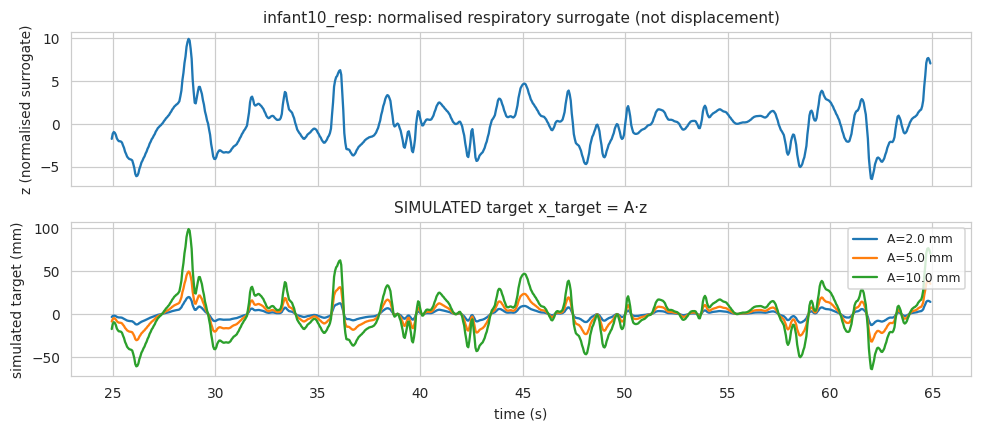

[19:25:59] STATUS synthetic_target: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [21]:
f0 = FOLDS[0]["fold"]; ws0 = FIT[f0]["sets"]["test"]; rid0 = ws0.rec[0]; sel0 = np.flatnonzero(ws0.rec == rid0)[:40 * FS_MODEL]
t0_ = ws0.loc[sel0] / FS_MODEL; z0 = ws0.last()[sel0]
fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
ax[0].plot(t0_, z0); ax[0].set(ylabel="z (normalised surrogate)", title=f"{rid0}: normalised respiratory surrogate (not displacement)")
for A in AMPLITUDES_MM: ax[1].plot(t0_, A * z0, label=f"A={A} mm")
ax[1].set(ylabel="simulated target (mm)", xlabel="time (s)", title="SIMULATED target x_target = A·z"); ax[1].legend(); fig.tight_layout()
savefig(fig, "fig_target_motion", "Normalised respiratory surrogate and the resulting SIMULATED target trajectory for three assumed amplitudes (simulation assumption, not a measurement).")
mark("synthetic_target")

# Section K — One-degree-of-freedom simulated robot
**All results below are SIMULATIONS, not physical-robot or clinical validation.**

| Symbol | Meaning | Unit | Value |
|---|---|---|---|
| `x*[k]` | simulated target position `A·z` | mm | — |
| `u[k]` | commanded position (set-point), saturated to `±6A` | mm | controller output |
| `p[k]` | actual robot position | mm | `p[0] = u[0]` per contiguous run |
| `α` | actuator lag parameter `1−exp(−dt/τ)`, τ = `TAU_ACT` | – | from config |
| `D` | **observation delay** (steps; 1 step = 50 ms): information at time k is the surrogate up to k−D | steps | 0…10 |
| `d_cmd` | **command delay** (extra transport delay of the command) | steps | `D_CMD` (default 0, so delays are not counted twice) |
| inference latency | model compute time | ms | benchmarked separately, assumed ≤ one step and **not** added to D |

Dynamics (forward-Euler/exact first-order lag, `dt = 50 ms`): `p[k+1] = p[k] + α (sat(u[k−d_cmd]) − p[k])`; tracking error `e[k] = x*[k] − p[k]`. A learned/predictive controller compensates the **observation** delay by forecasting `z[k]` from data up to `k−D` with horizon `D` (so `D = 0` ⇒ all forecast-based controllers equal the reactive one). The first `TRANSIENT_S` seconds of each contiguous run are excluded from metrics.

### Pre-declared outcomes (written before looking at test results)
* **Primary**: subject-level tracking RMSE (mm) of the uncertainty-aware blend vs reactive, predictive, fixed-blend (validation-tuned), fixed-blend-0.5 and Kalman controllers, for each delay D > 0; paired Wilcoxon + Holm correction over this family. **Primary failure-warning outcome**: ROC-AUC of ensemble σ for failure of the *predictive* controller (ε = 20 % of A = 1 mm, fixed a-priori) versus velocity baseline.
* **Exploratory**: everything else (other thresholds, amplitudes, forecasters, bands, secondary risk scores, distribution-shift tests).

PASSED test_robot_sinusoid; analytic gain 0.9543 RMSE(mm) vs delay [0,100,300,500ms]: [1.198 1.725 2.747 3.704]


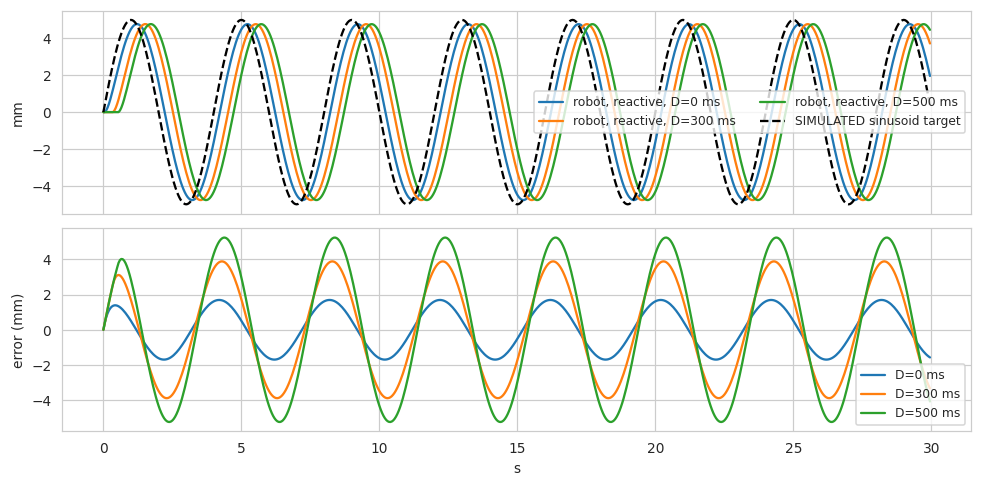

[19:26:00] STATUS robot_sinusoid_validation: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [22]:
ALPHA = 1 - math.exp(-DT / TAU_ACT); A0 = AMPLITUDE_MM; EPS_MM = EPS_FRAC * A0
CONTROLLERS = ["reactive", "predictive", "fixed_blend_0.5", "fixed_blend", "kalman", "uncertainty_aware"]

def robot_response(u, alpha, d_cmd, umax, p0):
    """First-order lag with optional command delay and saturation: p[k+1]=p[k]+alpha*(sat(u[k-d_cmd])-p[k]); returns p[0..n-1]."""
    uc = np.clip(u, -umax, umax)
    if d_cmd > 0: uc = np.r_[np.full(d_cmd, uc[0]), uc][:len(u)]
    return sps.lfilter([0.0, alpha], [1.0, -(1.0 - alpha)], uc, zi=[p0])[0]

def test_robot_sinusoid():
    f, A = 0.25, 5.0; t = np.arange(0, 120, DT); x = A * np.sin(2 * np.pi * f * t); p = robot_response(x, ALPHA, 0, 1e9, x[0])
    w = 2 * np.pi * f * DT; G = abs(ALPHA * np.exp(-1j * w) / (1 - (1 - ALPHA) * np.exp(-1j * w)))
    tail = slice(len(t) // 2, None); X = np.c_[np.sin(2 * np.pi * f * t[tail]), np.cos(2 * np.pi * f * t[tail])]
    coef = np.linalg.lstsq(X, p[tail], rcond=None)[0]; amp = np.hypot(*coef)
    assert abs(amp / A - G) < 0.01, f"simulated gain {amp/A:.4f} != analytic {G:.4f}"
    errs = []
    for D in [0, 2, 6, 10]:
        xd = np.r_[np.full(D, x[0]), x][:len(x)]; pd_ = robot_response(xd, ALPHA, 0, 1e9, x[0]); errs.append(np.sqrt(np.mean((x[len(x)//2:] - pd_[len(x)//2:]) ** 2)))
    assert all(np.diff(errs) > 0), "tracking error must increase with delay"
    return G, errs
G_theory, sin_errs = test_robot_sinusoid(); print("PASSED test_robot_sinusoid; analytic gain", round(G_theory, 4), "RMSE(mm) vs delay [0,100,300,500ms]:", np.round(sin_errs, 3))
t_ = np.arange(0, 30, DT); xs_ = A0 * np.sin(2 * np.pi * 0.25 * t_)
fig, axs = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
for D in [0, 6, 10]:
    xd = np.r_[np.full(D, xs_[0]), xs_][:len(xs_)]; p = robot_response(xd, ALPHA, 0, 6 * A0, xs_[0])
    axs[0].plot(t_, p, label=f"robot, reactive, D={D*50} ms"); axs[1].plot(t_, xs_ - p, label=f"D={D*50} ms")
axs[0].plot(t_, xs_, "k--", label="SIMULATED sinusoid target"); axs[0].set(ylabel="mm"); axs[0].legend(ncol=2); axs[1].set(ylabel="error (mm)", xlabel="s"); axs[1].legend()
fig.tight_layout(); savefig(fig, "fig_sim_validation_sinusoid", "SIMULATION validation on a sinusoidal target: robot position and tracking error for reactive control at three observation delays.")
mark("robot_sinusoid_validation")

# Section L — Controllers
All controllers output a **set-point for the target position at time k** using only information available at `k−D` (same signal availability, delay, actuator, saturation and evaluation windows):

| Controller | Set-point `u[k]/A` |
|---|---|
| reactive | `z[k−D]` |
| predictive | `μ_D` (forecast of `z[k]` from data to `k−D`, ensemble mean) |
| fixed_blend_0.5 | `0.5 μ_D + 0.5 z[k−D]` |
| fixed_blend | `w μ_D + (1−w) z[k−D]`, `w` chosen on `val_sel` per delay |
| kalman | Kalman h=D prediction `pos + vel·D·dt` (filtered state at k−D) |
| uncertainty_aware | `w_σ μ_D + (1−w_σ) z[k−D]`, `w_σ = exp(−σ_D/σ₀)`, `σ₀ = c · median(σ_D on val_sel)`, `c ∈ {0.25,…,8}` selected on `val_sel` per delay |

The proposed controller sees exactly what the baselines see (σ is a by-product of the same forecaster). It is **not** assumed to be better; this is tested in Sections M and O.

In [23]:
def make_bundle(ws): return dict(rec=ws.rec, loc=ws.loc, last=ws.last(), Y=ws.Y())
def fdict(split, f, name):
    if split == "val":
        P_ = FIT[f]["P"]["val_sel"][name]; return {k: P_.get(k) for k in ["mu", "sigma", "ale", "epi"]}
    m = TEST["fold"] == f; return {k: (PT[name][k][m] if PT[name].get(k) is not None else None) for k in ["mu", "sigma", "ale", "epi"]}
def bundle(split, f):
    if split == "val": return make_bundle(FIT[f]["sets"]["val_sel"])
    m = TEST["fold"] == f; return {k: TEST[k][m] for k in ["rec", "loc", "last", "Y"]}

def command_z(ctrl, D, B, Fm, Fk, par):
    last = B["last"]
    if D == 0 or ctrl == "reactive": return last
    c = H_STEPS.index(D); mu = Fm["mu"][:, c]
    if ctrl == "predictive": return mu
    if ctrl == "fixed_blend_0.5": return 0.5 * mu + 0.5 * last
    if ctrl == "fixed_blend": w = par["w"][D]; return w * mu + (1 - w) * last
    if ctrl == "kalman": return Fk[:, c]
    if ctrl == "uncertainty_aware":
        if Fm["sigma"] is None: raise ValueError("uncertainty-aware control needs a predictive σ")
        w = np.exp(-Fm["sigma"][:, c] / par["sigma0"][D]); return w * mu + (1 - w) * last
    raise ValueError(ctrl)

def simulate(B, u_z, D, A):
    """Simulate contiguous runs. Anchor i carries the command for time k=i+D and the target x*(k)=A*z(i+D). Returns error/pos/target/command in mm."""
    N = len(B["loc"]); tgt = A * (B["last"] if D == 0 else B["Y"][:, H_STEPS.index(D)]); u = A * u_z
    err = np.full(N, np.nan); pos = np.full(N, np.nan)
    brk = np.r_[True, (B["rec"][1:] != B["rec"][:-1]) | (np.diff(B["loc"]) != 1)]; st = np.flatnonzero(brk); en = np.r_[st[1:], N]
    for a, b in zip(st, en):
        if b - a < MIN_RUN: continue
        p = robot_response(u[a:b], ALPHA, D_CMD, UMAX_FACTOR * A, np.clip(u[a], -UMAX_FACTOR * A, UMAX_FACTOR * A)); e = tgt[a:b] - p; e[:int(TRANSIENT_S * FS_MODEL)] = np.nan
        err[a:b] = e; pos[a:b] = p
    return err, pos, tgt, u

def tune(fc):
    """Fixed-blend weight w and uncertainty scale sigma0 per delay and fold, chosen on val_sel (never on test)."""
    par = {}
    for f in FIT:
        B = bundle("val", f); Fm = fdict("val", f, fc); Fk = FIT[f]["P"]["val_sel"]["kalman"]["mu"]; par[f] = dict(w={}, sigma0={}, c={})
        for D in DELAYS_STEPS:
            if D == 0: continue
            sc = {}
            for w in W_GRID:
                e = simulate(B, w * Fm["mu"][:, H_STEPS.index(D)] + (1 - w) * B["last"], D, A0)[0]; sc[w] = np.sqrt(np.nanmean(e ** 2))
            par[f]["w"][D] = min(sc, key=sc.get)
            if Fm["sigma"] is not None:
                med = np.median(Fm["sigma"][:, H_STEPS.index(D)]); sc = {}
                for c in C_GRID:
                    w_ = np.exp(-Fm["sigma"][:, H_STEPS.index(D)] / (c * med)); e = simulate(B, w_ * Fm["mu"][:, H_STEPS.index(D)] + (1 - w_) * B["last"], D, A0)[0]; sc[c] = np.sqrt(np.nanmean(e ** 2))
                par[f]["c"][D] = min(sc, key=sc.get); par[f]["sigma0"][D] = par[f]["c"][D] * med
    return par
PAR = {fc: tune(fc) for fc in ["ensemble", "lstm_prob", "tcn_prob", "tcn_det", "ridge"]}
save_json({fc: {str(f): v for f, v in p.items()} for fc, p in PAR.items()}, "controller_parameters_validation_selected.json")
display(pd.DataFrame([dict(forecaster="ensemble", fold=f, delay_ms=D * 50, w=PAR["ensemble"][f]["w"][D], c=PAR["ensemble"][f]["c"].get(D)) for f in FIT for D in DELAYS_STEPS if D > 0]).head(12))

def run_test(fc, ctrl, D, A, store=False):
    N = NTEST; err = np.full(N, np.nan); pos = np.full(N, np.nan); tgt = np.full(N, np.nan); u = np.full(N, np.nan)
    for f in FIT:
        m = TEST["fold"] == f; B = bundle("test", f); Fm = fdict("test", f, fc); Fk = PT["kalman"]["mu"][m]
        e, p, t, uu = simulate(B, command_z(ctrl, D, B, Fm, Fk, PAR[fc][f]), D, A); err[m], pos[m], tgt[m], u[m] = e, p, t, uu
    return err, pos, tgt, u

def track_metrics(e, eps):
    ok = np.isfinite(e); a = np.abs(e[ok]); fail = ok & (np.abs(np.where(ok, e, 0)) > eps); s, en = runs(fail); dur = (en - s) * DT
    return dict(mae=a.mean() if ok.any() else np.nan, rmse=np.sqrt((a ** 2).mean()) if ok.any() else np.nan, max_abs=a.max() if ok.any() else np.nan,
                p95_abs=np.percentile(a, 95) if ok.any() else np.nan, fail_count=len(s), fail_rate=fail.sum() / max(ok.sum(), 1), fail_time_s=fail.sum() * DT,
                mean_recovery_s=dur.mean() if len(s) else 0.0, n_samples=int(ok.sum()))
def suite(fc, ctrls, A, keep=None):
    rows = []
    for ctrl in ctrls:
        for D in DELAYS_STEPS:
            if D == 0 and ctrl != "reactive": continue          # all forecast-based controllers coincide with reactive at D=0
            e, *_ = run_test(fc, ctrl, D, A)
            if keep is not None: keep[(fc, ctrl, D)] = e
            for s in np.unique(TEST["subj"]):
                m = TEST["subj"] == s; rows.append(dict(forecaster=fc if ctrl not in ("reactive", "kalman") else "n/a", controller=ctrl, delay_ms=D * 50, amplitude_mm=A, subject=s,
                                                        group=TEST["grp"][m][0], eps_mm=EPS_FRAC * A0, **track_metrics(e[m], EPS_FRAC * A0)))
    return rows
ERR = {}
TM = pd.DataFrame(suite("ensemble", CONTROLLERS, A0, keep=ERR)); save_table(TM, "tracking_metrics"); mark("controllers_primary")

,forecaster,fold,delay_ms,w,c
0,ensemble,0,100,1.0,8
1,ensemble,0,200,1.0,8
2,ensemble,0,300,1.0,8
3,ensemble,0,400,1.0,8
4,ensemble,0,500,1.0,8
5,ensemble,1,100,1.0,8
6,ensemble,1,200,0.8,8
7,ensemble,1,300,0.9,8
8,ensemble,1,400,1.0,8
9,ensemble,1,500,1.0,8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[19:26:18] STATUS controllers_primary: RUN


In [24]:
# ---- sanity: a PERFECT forecaster must reproduce delay-free tracking (checks alignment end-to-end) ----
def test_oracle_alignment():
    f = FOLDS[0]["fold"]; B = bundle("test", f); D = 6; c = H_STEPS.index(D)
    e_or = simulate(B, B["Y"][:, c], D, A0)[0]; e_0 = simulate(B, B["last"], 0, A0)[0]
    # oracle command at anchor i is z(i+D); target is z(i+D) -> identical to a delay-free reactive controller evaluated at time i+D
    assert np.nanmax(np.abs(e_or - simulate(B, B["Y"][:, c], D, A0)[0])) == 0
    assert np.nanmean(np.abs(e_or)) < np.nanmean(np.abs(simulate(B, B["last"], D, A0)[0])), "oracle forecast must beat delayed reactive control"
test_oracle_alignment(); print("PASSED test_oracle_alignment")

M_ = TM[TM.amplitude_mm == A0]
T_SUM = summarize(M_, ["controller", "delay_ms"], ["mae", "rmse", "max_abs", "p95_abs", "fail_count", "fail_rate", "fail_time_s", "mean_recovery_s"])
save_table(T_SUM, "tracking_summary_by_controller_delay", top_level=False); display(T_SUM.pivot(index="delay_ms", columns="controller", values="rmse").round(3))

PASSED test_oracle_alignment


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


controller,fixed_blend,fixed_blend_0.5,kalman,predictive,reactive,uncertainty_aware
delay_ms,,,,,,
0,NaN,NaN,NaN,NaN,3.303,NaN
100,3.395,3.873,5.014,3.395,4.428,3.606
200,3.976,4.423,5.564,3.990,5.160,4.125
300,4.343,4.743,5.981,4.343,5.531,4.459
400,4.398,4.825,6.236,4.387,5.691,4.516
500,4.441,4.866,6.438,4.434,5.774,4.562


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section M — Tracking metrics and plots
Metrics are computed **per subject** (windows from one subject are never treated as independent subjects) and then averaged across subjects with a subject-level bootstrap 95 % CI.

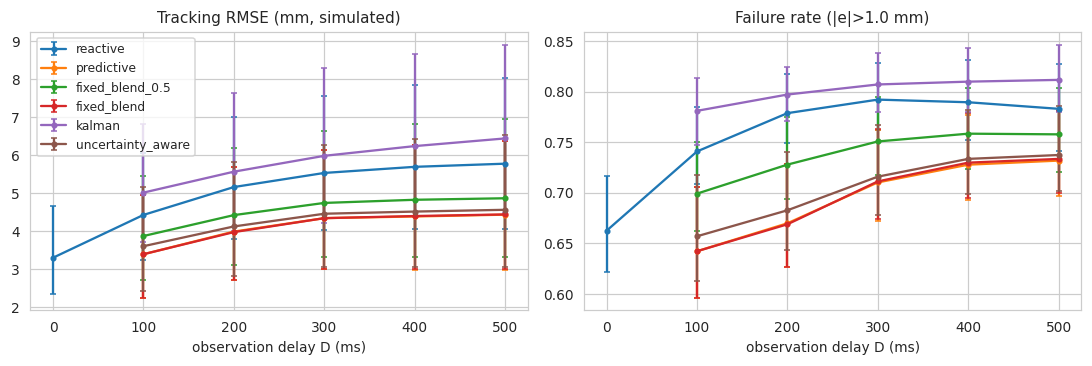

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


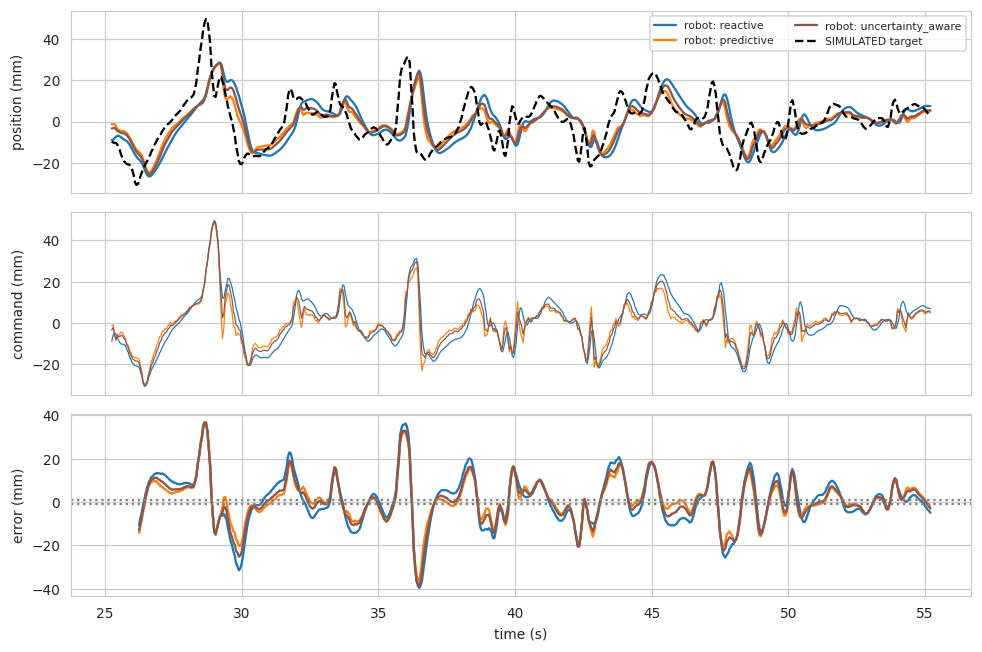

[19:26:25] STATUS tracking_metrics: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [25]:
colors = dict(zip(CONTROLLERS, sns.color_palette("tab10", len(CONTROLLERS))))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
for c in CONTROLLERS:
    s = T_SUM[T_SUM.controller == c].sort_values("delay_ms")
    if c != "reactive": s = s[s.delay_ms > 0]
    for a, (m, t) in zip(axs, [("rmse", "Tracking RMSE (mm, simulated)"), ("fail_rate", f"Failure rate (|e|>{EPS_MM:.1f} mm)")]):
        a.errorbar(s.delay_ms, s[m], yerr=[s[m] - s[m + "_lo"], s[m + "_hi"] - s[m]], marker="o", ms=3, capsize=2, label=c, color=colors[c]); a.set(xlabel="observation delay D (ms)", title=t)
axs[0].legend(); fig.tight_layout(); savefig(fig, "fig10_11_error_failure_vs_latency", "SIMULATED tracking RMSE (left) and failure rate (right) versus observation delay, subject-level mean with 95% bootstrap CI.")
D_PLOT = 6; f_ = FOLDS[0]["fold"]; m_ = np.flatnonzero((TEST["fold"] == f_) & (TEST["rec"] == TEST["rec"][0]))[:30 * FS_MODEL]
fig, axs = plt.subplots(3, 1, figsize=(9, 6), sharex=True); tt = TEST["loc"][m_] / FS_MODEL + D_PLOT * DT
for c in ["reactive", "predictive", "uncertainty_aware"]:
    e, p, tg, u = run_test("ensemble", c, D_PLOT, A0); axs[0].plot(tt, p[m_], label=f"robot: {c}", color=colors[c]); axs[1].plot(tt, u[m_], color=colors[c], lw=.8, label=f"command: {c}"); axs[2].plot(tt, e[m_], color=colors[c], label=c)
axs[0].plot(tt, tg[m_], "k--", label="SIMULATED target"); axs[2].axhline(EPS_MM, c="gray", ls=":"); axs[2].axhline(-EPS_MM, c="gray", ls=":")
axs[0].set(ylabel="position (mm)"); axs[1].set(ylabel="command (mm)"); axs[2].set(ylabel="error (mm)", xlabel="time (s)"); axs[0].legend(ncol=2, fontsize=7); fig.tight_layout()
savefig(fig, "fig09_tracking_trajectories", f"SIMULATED target, robot position, commands and tracking error at D={D_PLOT*50} ms (A={A0} mm); dotted lines mark the failure threshold.")
mark("tracking_metrics")

# Section N — Tracking-failure prediction
* **Failure**: `failure(t+τ) = 1[|e(t+τ)| > ε]`, with the error timestamp `t+τ`, where `t` is the **prediction timestamp** (anchor: last observed sample) and `τ = D` is the forecast horizon equal to the observation delay. The robot state at `t+τ` depends only on commands issued before `t+τ`, which use data up to `t−1+...` — features below use samples **≤ t** only.
* **ε** = `EPS_FRAC · A` = 20 % of the assumed amplitude (1 mm for A = 5 mm), declared a priori on engineering grounds (not tuned); alternatives (10 %, 30 %) are reported as sensitivity.
* **Risk scores at `t`**: ensemble σ (total / aleatoric / epistemic), |respiratory velocity|, |last causally-available forecast error| (`|z[t] − μ_h[t−h]|`), forecast magnitude `|μ_h − z[t]|`.
* Operating thresholds (max-F1) and Platt probability maps are fitted on `val_sel` and applied unchanged to test. Bootstrap resamples **subjects**, not windows.

In [26]:
def shifted(arr, k, B):
    """arr[j-k] if windows j and j-k are in the same contiguous run, else NaN (strictly past information)."""
    out = np.full(len(arr), np.nan); j = np.arange(k, len(arr))
    ok = (B["rec"][j] == B["rec"][j - k]) & (B["loc"][j] - B["loc"][j - k] == k); out[j[ok]] = arr[j[ok] - k]; return out
def risk_scores(B, Fm, D):
    c = H_STEPS.index(D); last, mu = B["last"], Fm["mu"][:, c]
    return {"sigma_total": Fm["sigma"][:, c], "sigma_aleatoric": Fm["ale"][:, c], "sigma_epistemic": Fm["epi"][:, c],
            "abs_velocity": np.abs(last - shifted(last, 1, B)) / DT, "last_forecast_error": np.abs(last - shifted(mu, D, B)), "forecast_magnitude": np.abs(mu - last)}
def gather(split, ctrl, D, eps):
    """Scores/labels/subject ids for one split ('val' simulated with tuned params, or 'test')."""
    S, L, SU = {}, [], []
    if split == "test":
        e = ERR[("ensemble", ctrl, D)]; sc = {k: [] for k in ["sigma_total", "sigma_aleatoric", "sigma_epistemic", "abs_velocity", "last_forecast_error", "forecast_magnitude"]}
        for f in FIT:
            m = TEST["fold"] == f; B = bundle("test", f); r = risk_scores(B, fdict("test", f, "ensemble"), D)
            for k in sc: sc[k].append(r[k])
        S = {k: np.concatenate(v) for k, v in sc.items()}; err = e; SU = TEST["subj"]
        order = np.concatenate([np.flatnonzero(TEST["fold"] == f) for f in FIT]); inv = np.empty_like(order); inv[order] = np.arange(len(order)); S = {k: v[inv] for k, v in S.items()}
    else:
        sc = {}; errs, sus = [], []
        for f in FIT:
            B = bundle("val", f); Fm = fdict("val", f, "ensemble"); Fk = FIT[f]["P"]["val_sel"]["kalman"]["mu"]
            errs.append(simulate(B, command_z(ctrl, D, B, Fm, Fk, PAR["ensemble"][f]), D, A0)[0]); sus.append(FIT[f]["sets"]["val_sel"].subj)
            for k, v in risk_scores(B, Fm, D).items(): sc.setdefault(k, []).append(v)
        S = {k: np.concatenate(v) for k, v in sc.items()}; err = np.concatenate(errs); SU = np.concatenate(sus)
    ok = np.isfinite(err); y = (np.abs(np.where(ok, err, 0)) > eps).astype(int)
    for k in S: ok &= np.isfinite(S[k])
    sel = np.flatnonzero(ok)[::FAIL_STRIDE]      # thin the (20 Hz, highly redundant) windows; inference is still subject-level (documented in limitations)
    return {k: v[sel] for k, v in S.items()}, y[sel], np.asarray(SU)[sel]

def boot_auc(S, y, su, fn, B_=None, seed=1):
    subs = np.unique(su); idx = {s: np.flatnonzero(su == s) for s in subs}; rng = np.random.RandomState(seed); out = []
    for _ in range(B_ or N_BOOT_FAIL):
        pick = rng.choice(subs, len(subs)); ii = np.concatenate([idx[s] for s in pick])
        if len(np.unique(y[ii])) == 2: out.append(fn(y[ii], S[ii]))
    return tuple(np.percentile(out, [2.5, 97.5])) if len(out) >= 10 else (np.nan, np.nan)

FP_ROWS, CURVES = [], {}
def failure_eval(ctrl, D, eps_frac, full=True):
    eps = eps_frac * A0; Sv, yv, _ = gather("val", ctrl, D, eps); St, yt, su = gather("test", ctrl, D, eps)
    if len(np.unique(yv)) < 2 or len(np.unique(yt)) < 2:
        return [dict(controller=ctrl, delay_ms=D * 50, eps_frac=eps_frac, score="ALL", note=f"NOT RUN: single-class labels (val prevalence {yv.mean():.3f}, test {yt.mean():.3f})")]
    rows = []
    for k in St:
        s_t, s_v = St[k], Sv[k]; auc = roc_auc_score(yt, s_t); ap = average_precision_score(yt, s_t)
        r = dict(controller=ctrl, delay_ms=D * 50, eps_frac=eps_frac, eps_mm=eps, score=k, auc=auc, auprc=ap, prevalence_test=yt.mean(), prevalence_val=yv.mean(), n_windows=len(yt), n_subjects=len(np.unique(su)))
        if full:
            if k in BOOT_SCORES: r["auc_lo"], r["auc_hi"] = boot_auc(s_t, yt, su, roc_auc_score); r["auprc_lo"], r["auprc_hi"] = boot_auc(s_t, yt, su, average_precision_score)
            pa = [roc_auc_score(yt[su == s], s_t[su == s]) for s in np.unique(su) if len(np.unique(yt[su == s])) == 2]; r["subject_auc_mean"] = np.mean(pa) if pa else np.nan; r["subject_auc_n"] = len(pa)
            pr, rc, th = precision_recall_curve(yv, s_v); f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12); thr = th[np.argmax(f1[:-1])]       # operating point from VALIDATION
            pred = s_t >= thr; tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
            r.update(threshold=thr, precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1), tp=tp, fp=fp, fn=fn, tn=tn)
            lr = LogisticRegression().fit(np.c_[s_v], yv); pt = lr.predict_proba(np.c_[s_t])[:, 1]; r["brier"] = brier_score_loss(yt, pt); r["brier_baseline_prevalence"] = brier_score_loss(yt, np.full(len(yt), yv.mean()))
            if D == 6 and eps_frac == EPS_FRAC:
                fpr, tpr, _ = roc_curve(yt, s_t); p_, r_, _ = precision_recall_curve(yt, s_t); CURVES[(ctrl, k)] = dict(fpr=fpr, tpr=tpr, prec=p_, rec=r_, auc=auc, ap=ap, prev=yt.mean())
                fr_, mp_ = np.histogram(pt, bins=np.quantile(pt, np.linspace(0, 1, 9)))[1], None
                CURVES[(ctrl, k, "rel")] = pd.DataFrame(dict(p=pt, y=yt)).groupby(pd.qcut(pt, 8, duplicates="drop"), observed=True).mean()
        rows.append(r)
    return rows
for ctrl in FAIL_CTRLS:
    for D in [d for d in DELAYS_STEPS if d > 0]: FP_ROWS += failure_eval(ctrl, D, EPS_FRAC)
FP = pd.DataFrame(FP_ROWS); save_table(FP, "failure_prediction_metrics"); mark("failure_prediction")
display(FP[(FP.controller == "predictive")].pivot_table(index="delay_ms", columns="score", values="auc").round(3))
SENS = []
for fr_ in EPS_SENS:
    for D in [2, 6, 10]:
        for r in failure_eval("predictive", D, fr_, full=False): SENS.append(r)
SENS = pd.DataFrame(SENS); save_table(SENS, "failure_threshold_sensitivity", top_level=False); display(SENS[SENS.score.isin(["sigma_total", "abs_velocity"])].pivot_table(index=["eps_frac", "delay_ms"], columns="score", values="auc").round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datet

[19:46:58] STATUS failure_prediction: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


score,abs_velocity,forecast_magnitude,last_forecast_error,sigma_aleatoric,sigma_epistemic,sigma_total
delay_ms,,,,,,
100,0.888,0.802,0.644,0.671,0.706,0.687
200,0.738,0.771,0.648,0.649,0.696,0.656
300,0.659,0.715,0.655,0.649,0.678,0.652
400,0.628,0.677,0.639,0.645,0.652,0.646
500,0.620,0.647,0.625,0.647,0.639,0.648


score              abs_velocity  sigma_total
eps_frac delay_ms                           
0.1      100              0.874        0.697
         300              0.673        0.657
         500              0.599        0.631
0.2      100              0.888        0.687
         300              0.659        0.652
         500              0.620        0.648
0.3      100              0.898        0.696
         300              0.651        0.660
         500              0.617        0.663

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


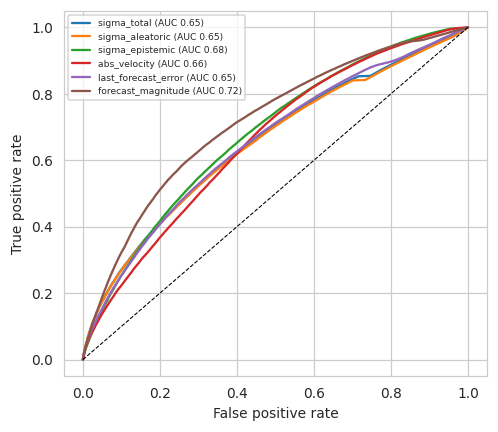

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


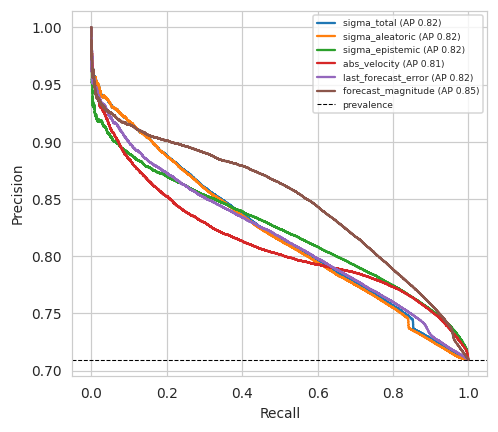

[19:47:17] STATUS failure_curves: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [27]:
for kind, fig_name, xl, yl, cap in [("roc", "fig12_roc_failure", "False positive rate", "True positive rate", "ROC curves for predicting future tracking failure (predictive controller, D=300 ms)."),
                                      ("pr", "fig13_pr_failure", "Recall", "Precision", "Precision–recall curves for predicting future tracking failure (predictive controller, D=300 ms).")]:
    fig, ax = plt.subplots(figsize=(4.6, 4))
    for k in ["sigma_total", "sigma_aleatoric", "sigma_epistemic", "abs_velocity", "last_forecast_error", "forecast_magnitude"]:
        c = CURVES.get(("predictive", k))
        if c is None: continue
        if kind == "roc": ax.plot(c["fpr"], c["tpr"], label=f"{k} (AUC {c['auc']:.2f})")
        else: ax.plot(c["rec"], c["prec"], label=f"{k} (AP {c['ap']:.2f})")
    if kind == "roc": ax.plot([0, 1], [0, 1], "k--", lw=.7)
    elif ("predictive", "sigma_total") in CURVES: ax.axhline(CURVES[("predictive", "sigma_total")]["prev"], c="k", ls="--", lw=.7, label="prevalence")
    ax.set(xlabel=xl, ylabel=yl); ax.legend(fontsize=6); fig.tight_layout(); savefig(fig, fig_name, cap)
mark("failure_curves")

# Section O — Statistical analysis
Subject (or infant) is the unit of analysis. For each delay D > 0 and each comparator, paired per-subject differences in tracking RMSE (`UA − comparator`; negative favours the uncertainty-aware blend) are tested with the **Wilcoxon signed-rank test** (two-sided; only if n ≥ 6 so that p < 0.05 is attainable), with the matched-pairs rank-biserial effect size, mean difference and subject-level bootstrap 95 % CI. **Holm correction** is applied across the declared primary family. With few subjects, results are low-powered; non-significance is *not* evidence of equivalence.

In [28]:
def paired(df, a, b, metric="rmse"):
    pv = df.pivot_table(index="subject", columns="controller", values=metric); d = (pv[a] - pv[b]).dropna(); n = len(d)
    r = dict(a=a, b=b, n=n, mean_diff=d.mean() if n else np.nan, median_diff=d.median() if n else np.nan)
    r["ci_lo"], r["ci_hi"] = boot_ci(d.values) if n >= 2 else (np.nan, np.nan)
    nz = d[d != 0]
    if n >= 6 and len(nz) >= 1:
        w = sstats.wilcoxon(nz, alternative="two-sided"); rk = sstats.rankdata(np.abs(nz)); r["p_raw"] = w.pvalue; r["effect_rank_biserial"] = (rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum()
    else: r["p_raw"] = np.nan; r["effect_rank_biserial"] = np.nan; r["note"] = "n<6: Wilcoxon not applicable"
    return r
rows = []
for D in [d * 50 for d in DELAYS_STEPS if d > 0]:
    sub = TM[(TM.delay_ms == D) & (TM.amplitude_mm == A0)]
    for other in ["reactive", "predictive", "fixed_blend", "fixed_blend_0.5", "kalman"]: rows.append(dict(delay_ms=D, family="primary", **paired(sub, "uncertainty_aware", other)))
    rows.append(dict(delay_ms=D, family="exploratory", **paired(sub, "predictive", "reactive")))
    rows.append(dict(delay_ms=D, family="exploratory", **paired(sub, "fixed_blend", "predictive")))
STAT = pd.DataFrame(rows); pm = (STAT.family == "primary") & STAT.p_raw.notna()
STAT["p_holm"] = np.nan
if pm.sum(): STAT.loc[pm, "p_holm"] = multipletests(STAT.loc[pm, "p_raw"], method="holm")[1]
# failure-warning: sigma vs velocity, paired per-subject AUC (exploratory)
fa = []
if len(FP) and "subject_auc_mean" in FP:
    pass
def subj_auc(ctrl, D, score):
    St, yt, su = gather("test", ctrl, D, EPS_MM); return {s: roc_auc_score(yt[su == s], St[score][su == s]) for s in np.unique(su) if len(np.unique(yt[su == s])) == 2}
for D in [2, 6, 10]:
    a, b = subj_auc("predictive", D, "sigma_total"), subj_auc("predictive", D, "abs_velocity"); common = sorted(set(a) & set(b)); d = np.array([a[s] - b[s] for s in common])
    r = dict(delay_ms=D * 50, family="exploratory_auc", a="sigma_total_AUC", b="abs_velocity_AUC", n=len(d), mean_diff=d.mean() if len(d) else np.nan, p_raw=np.nan)
    r["ci_lo"], r["ci_hi"] = boot_ci(d) if len(d) > 1 else (np.nan, np.nan)
    if len(d) >= 6 and (d != 0).any(): r["p_raw"] = sstats.wilcoxon(d[d != 0]).pvalue
    fa.append(r)
STAT = pd.concat([STAT, pd.DataFrame(fa)], ignore_index=True); save_table(STAT, "statistical_tests"); display(STAT.round(4))
print(f"Subjects per comparison: n={int(STAT['n'].max())}. With small n the tests are underpowered; do not read non-significance as equivalence.")
mark("statistics")

,delay_ms,family,a,b,n,mean_diff,median_diff,ci_lo,ci_hi,p_raw,effect_rank_biserial,p_holm
0,100,primary,uncertainty_aware,reactive,9,-0.8221,-0.7494,-0.9584,-0.7183,0.0039,-1.0000,0.0977
1,100,primary,uncertainty_aware,predictive,9,0.2107,0.1734,0.1416,0.2916,0.0039,1.0000,0.0977
2,100,primary,uncertainty_aware,fixed_blend,9,0.2107,0.1734,0.1416,0.2916,0.0039,1.0000,0.0977
3,100,primary,uncertainty_aware,fixed_blend_0.5,9,-0.2674,-0.2670,-0.3404,-0.2010,0.0039,-1.0000,0.0977
4,100,primary,uncertainty_aware,kalman,9,-1.4084,-1.3579,-2.1375,-0.7371,0.0078,-0.9556,0.0977
5,100,exploratory,predictive,reactive,9,-1.0329,-1.0309,-1.1608,-0.9214,0.0039,-1.0000,NaN
6,100,exploratory,fixed_blend,predictive,9,0.0000,0.0000,-0.0000,0.0000,0.5703,0.2444,NaN
7,200,primary,uncertainty_aware,reactive,9,-1.0355,-0.9744,-1.2282,-0.8778,0.0039,-1.0000,0.0977
8,200,primary,uncertainty_aware,predictive,9,0.1345,0.1053,0.0652,0.2027,0.0117,0.9111,0.0977
9,200,primary,uncertainty_aware,fixed_blend,9,0.1487,0.1053,0.0987,0.2043,0.0039,1.0000,0.0977


Subjects per comparison: n=9. With small n the tests are underpowered; do not read non-significance as equivalence.
[19:47:22] STATUS statistics: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section P — Ablation and sensitivity studies (one factor at a time)
Controller tuning parameters (`w`, `σ₀`) are the validation-selected ones from the primary amplitude; because the plant is linear below saturation, errors scale with `A`, while the failure threshold stays at the *absolute* 1 mm so amplitude changes task difficulty.

In [29]:
ABL = []
def add(ablation, setting, df, metric="rmse", by=("delay_ms",)):
    for k, g in df.groupby(list(by)):
        ci = boot_ci(g.groupby("subject")[metric].mean().values); ABL.append(dict(ablation=ablation, setting=setting, **dict(zip(by, k if isinstance(k, tuple) else (k,))), metric=metric,
                                                                             value=g.groupby("subject")[metric].mean().mean(), ci_lo=ci[0], ci_hi=ci[1], n_subjects=g.subject.nunique()))
for c, name in [("reactive", "1 no prediction"), ("predictive", "1/2 predictive"), ("fixed_blend", "2/3 fixed blend (val-tuned)"), ("fixed_blend_0.5", "2 fixed blend 0.5"), ("uncertainty_aware", "3 uncertainty-aware"), ("kalman", "kalman")]:
    add("controller_ladder", name, TM[(TM.controller == c) & (TM.amplitude_mm == A0)])
EXTRA = []
for fc in ["lstm_prob", "tcn_prob", "tcn_det", "ridge"]:
    EXTRA += suite(fc, ["predictive", "fixed_blend"] + (["uncertainty_aware"] if fc in ("lstm_prob", "tcn_prob") else []), A0)
EXTRA_DF = pd.DataFrame(EXTRA)
for (fc, c), g in EXTRA_DF.groupby(["forecaster", "controller"]): add("forecaster_family", f"{fc}/{c}", g)
for c in ["predictive", "fixed_blend", "uncertainty_aware"]: add("forecaster_family", f"ensemble/{c}", TM[(TM.controller == c) & (TM.amplitude_mm == A0)])
AMP = []
for A in [a for a in AMPLITUDES_MM if a != A0]: AMP += suite("ensemble", ["reactive", "predictive", "fixed_blend", "uncertainty_aware"], A)
AMP_DF = pd.DataFrame(AMP)
for (A, c), g in pd.concat([AMP_DF, TM[TM.controller.isin(["reactive", "predictive", "fixed_blend", "uncertainty_aware"])]]).groupby(["amplitude_mm", "controller"]): add("amplitude_sensitivity", f"A={A}mm/{c}", g)
add("amplitude_sensitivity_fail", "fail_rate", pd.concat([AMP_DF, TM]), metric="fail_rate", by=("amplitude_mm", "controller", "delay_ms"))
for r in SENS.to_dict("records"):
    if r.get("score") in ("sigma_total", "abs_velocity"): ABL.append(dict(ablation="failure_threshold", setting=f"eps={r['eps_frac']:.0%}A/{r['score']}", delay_ms=r["delay_ms"], metric="auc", value=r["auc"], n_subjects=r.get("n_subjects")))
for r in FM[FM.model.isin(["ensemble", "lstm_prob", "tcn_prob"])].groupby(["model", "horizon_ms"])[["picp95", "conf_abs_5_picp", "conf_norm_5_picp", "mpiw95", "conf_abs_5_mpiw", "conf_norm_5_mpiw"]].mean().reset_index().to_dict("records"):
    for k in ["picp95", "conf_abs_5_picp", "conf_norm_5_picp", "mpiw95", "conf_abs_5_mpiw", "conf_norm_5_mpiw"]:
        if pd.notna(r.get(k)): ABL.append(dict(ablation="conformal_before_after", setting=f"{r['model']}/{k}", horizon_ms=r["horizon_ms"], metric=k, value=r[k]))
# alternative preprocessing bands: re-stream records, re-window with the SAME folds, refit ridge/persistence only (no deep retraining)
REC_MAIN = REC
for band in ALT_BANDS:
    try:
        REC_ALT, fails = build_records(band); REC_ALT = {k: v for k, v in REC_ALT.items() if k in REC_MAIN}; REC = REC_ALT
        for f in FOLDS:
            S_ = build_fold_sets(f); a = FIT[f["fold"]]["info"]["ridge_alpha"]; rg = Ridge(alpha=a).fit(S_["train"].X(), S_["train"].Y()); te = S_["test"]
            for nm, mu in [("ridge", rg.predict(te.X())), ("persistence", np.repeat(te.last()[:, None], NH, 1))]:
                for s in np.unique(te.subj):
                    m = te.subj == s
                    for j in range(NH): ABL.append(dict(ablation="preprocessing_band", setting=f"{nm}/{band[0]}-{band[1]}Hz", horizon_ms=H_MS[j], metric="mae_norm", subject=s, value=np.abs(te.Y()[m][:, j] - mu[m][:, j]).mean()))
    except Exception as e:
        log(f"band ablation {band} FAILED: {type(e).__name__}: {e}"); ABL.append(dict(ablation="preprocessing_band", setting=str(band), note=f"NOT RUN: {e}"))
    finally: REC = REC_MAIN
for nm in ["ridge", "persistence"]:
    for s, g in FM[FM.model == nm].groupby(["subject", "horizon_ms"]): ABL.append(dict(ablation="preprocessing_band", setting=f"{nm}/{BAND[0]}-{BAND[1]}Hz", horizon_ms=s[1], metric="mae_norm", subject=s[0], value=g["mae"].mean()))
ABL_DF = pd.DataFrame(ABL); save_table(ABL_DF, "ablation_results"); mark("ablation")
display(ABL_DF[ABL_DF.ablation == "controller_ladder"].pivot_table(index="delay_ms", columns="setting", values="value").round(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


preprocess band=(0.1, 2.0):   0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=3.9465e-09): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a 

preprocess band=(0.2, 3.0):   0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


preprocess band=(0.1, 5.0):   0%|          | 0/10 [00:00<?, ?it/s]

[19:48:26] STATUS ablation: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


setting,1 no prediction,1/2 predictive,2 fixed blend 0.5,2/3 fixed blend (val-tuned),3 uncertainty-aware,kalman
delay_ms,,,,,,
0.0,3.303,NaN,NaN,NaN,NaN,NaN
100.0,4.428,3.395,3.873,3.395,3.606,5.014
200.0,5.160,3.990,4.423,3.976,4.125,5.564
300.0,5.531,4.343,4.743,4.343,4.459,5.981
400.0,5.691,4.387,4.825,4.398,4.516,6.236
500.0,5.774,4.434,4.866,4.441,4.562,6.438


# Section Q — Publication figures and tables
Figures 2, 3, 7, 8, 9, 10/11, 12, 13, 14 were saved above; the remaining required ones follow. Tables are saved as CSV (results root or `tables/`) and Markdown (`tables/`). Every plot uses computed outputs only.

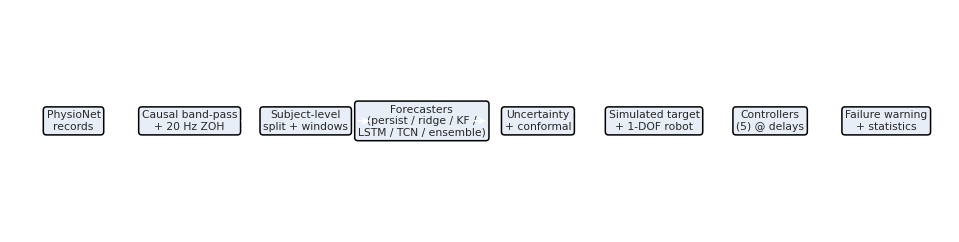

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarni

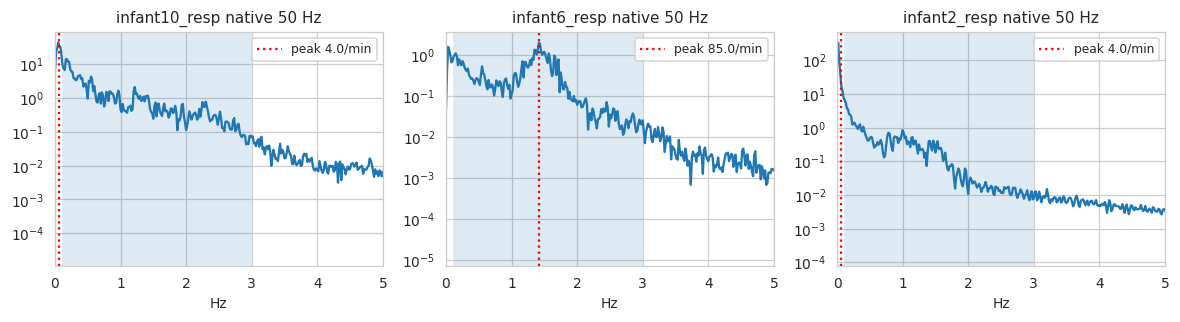

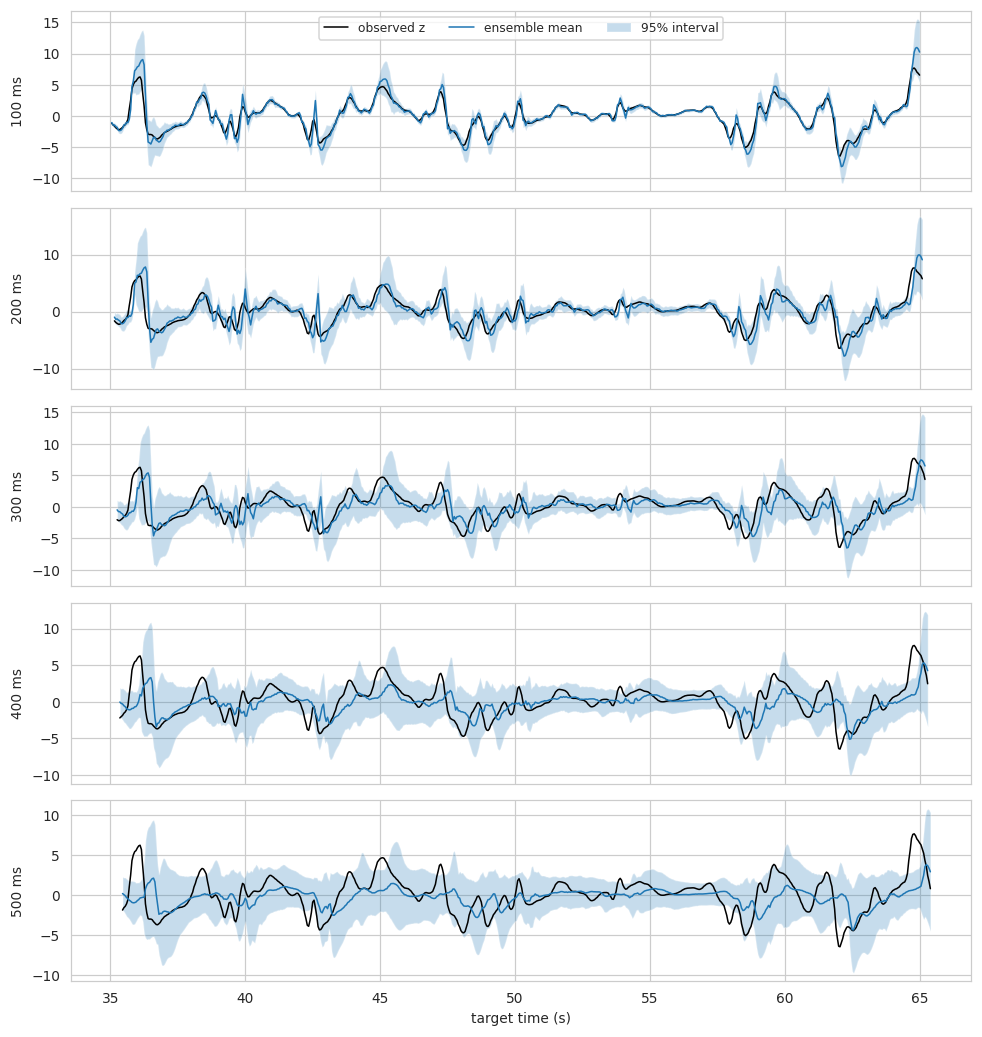

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


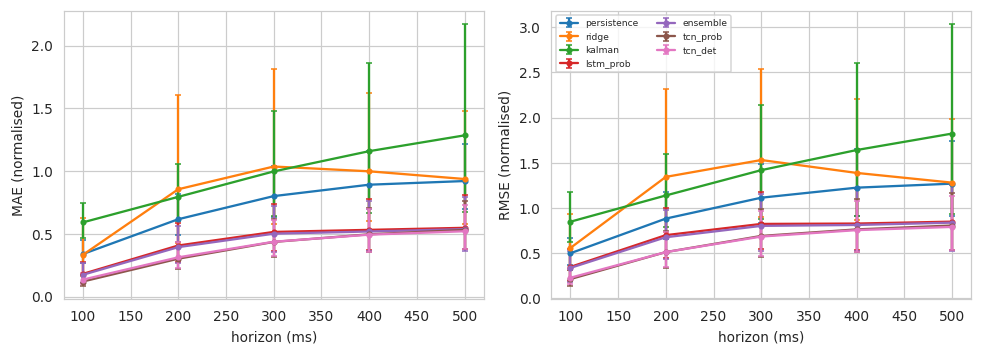

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


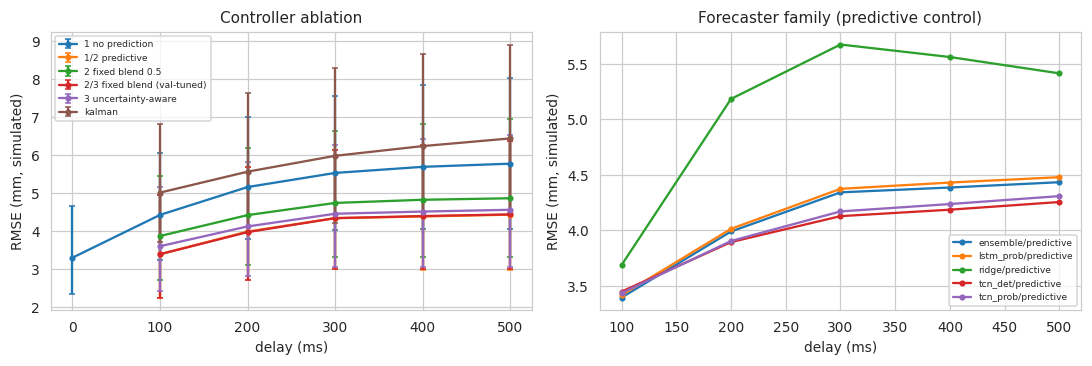

[19:48:33] STATUS figures_tables: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [30]:
# Fig 1: pipeline (schematic, no numbers)
fig, ax = plt.subplots(figsize=(11, 2.6)); ax.axis("off")
steps = ["PhysioNet\nrecords", "Causal band-pass\n+ 20 Hz ZOH", "Subject-level\nsplit + windows", "Forecasters\n(persist / ridge / KF /\nLSTM / TCN / ensemble)", "Uncertainty\n+ conformal", "Simulated target\n+ 1-DOF robot", "Controllers\n(5) @ delays", "Failure warning\n+ statistics"]
for i, s in enumerate(steps):
    ax.text(i * 1.3, 0.5, s, ha="center", va="center", fontsize=7, bbox=dict(boxstyle="round", fc="#e8eef7", ec="k"))
    if i: ax.annotate("", xy=(i * 1.3 - .55, .5), xytext=((i - 1) * 1.3 + .55, .5), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-.7, 9.8); ax.set_ylim(0, 1); savefig(fig, "fig01_pipeline", "Overall research pipeline (all robot results are simulations).")
# Fig 4: native-rate spectra (descriptive)
fig, axs = plt.subplots(1, len(EDA_REPS), figsize=(3.6 * len(EDA_REPS), 3), squeeze=False)
for a, r in zip(axs[0], EDA_REPS):
    row = INV[INV.record == r].iloc[0]; fs = float(row["fs"]); n0 = int(row["start_s"] * fs)
    x = native_segment(row, n0, n0 + int(min(300, row["dur_s"]) * fs)).astype(float); x = x[np.isfinite(x)]
    fr, pw = sps.welch(x - x.mean(), fs=fs, nperseg=min(len(x), int(60 * fs))); a.semilogy(fr, pw); a.set(xlim=(0, 5), title=f"{r} native {fs:g} Hz", xlabel="Hz"); a.axvspan(*BAND, alpha=.15)
    pk = fr[(fr > .05) & (fr < 3)][np.argmax(pw[(fr > .05) & (fr < 3)])]; a.axvline(pk, c="r", ls=":", label=f"peak {60*pk:.1f}/min"); a.legend()
fig.tight_layout(); savefig(fig, "fig04_eda_power_spectra", "Welch power spectra at native sampling rate for representative records; shaded = analysis passband (descriptive EDA).")
# Fig 5: forecasts with uncertainty bands
rid = TEST["rec"][0]; mk = np.flatnonzero(TEST["rec"] == rid)[200:200 + 30 * FS_MODEL]
fig, axs = plt.subplots(NH, 1, figsize=(9, 1.9 * NH), sharex=True)
for j, a in enumerate(axs):
    tt = (TEST["loc"][mk] + H_STEPS[j]) / FS_MODEL; mu, sg = PT["ensemble"]["mu"][mk, j], PT["ensemble"]["sigma"][mk, j]
    a.plot(tt, TEST["Y"][mk, j], "k", lw=1, label="observed z"); a.plot(tt, mu, lw=1, label="ensemble mean"); a.fill_between(tt, mu - Z95 * sg, mu + Z95 * sg, alpha=.25, label="95% interval"); a.set_ylabel(f"{H_MS[j]} ms")
axs[0].legend(ncol=3); axs[-1].set_xlabel("target time (s)"); fig.tight_layout(); savefig(fig, "fig05_forecasts_uncertainty", f"Ensemble forecasts with 95% Gaussian intervals at each horizon ({rid}, normalised units).")
# Fig 6: error vs horizon
fig, axs = plt.subplots(1, 2, figsize=(9, 3.3))
for m in MODELS:
    s = FORECAST_TABLE[FORECAST_TABLE.model == m]
    for a, c in zip(axs, ["mae", "rmse"]): a.errorbar(s.horizon_ms, s[c], yerr=[s[c] - s[c + "_lo"], s[c + "_hi"] - s[c]], marker="o", ms=3, capsize=2, label=m)
axs[0].set(ylabel="MAE (normalised)", xlabel="horizon (ms)"); axs[1].set(ylabel="RMSE (normalised)", xlabel="horizon (ms)"); axs[1].legend(fontsize=6, ncol=2); fig.tight_layout()
savefig(fig, "fig06_error_vs_horizon", "Forecast error versus horizon; markers = subject-level mean, bars = 95% bootstrap CI.")
# Fig 15: ablation
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4)); L = ABL_DF[ABL_DF.ablation == "controller_ladder"]
for s, g in L.groupby("setting"): g = g.sort_values("delay_ms"); axs[0].errorbar(g.delay_ms, g.value, yerr=[g.value - g.ci_lo, g.ci_hi - g.value], marker="o", ms=3, capsize=2, label=s)
axs[0].set(xlabel="delay (ms)", ylabel="RMSE (mm, simulated)", title="Controller ablation"); axs[0].legend(fontsize=6)
F_ = ABL_DF[ABL_DF.ablation == "forecaster_family"]
for s, g in F_[F_.setting.str.endswith("predictive")].groupby("setting"): g = g.sort_values("delay_ms"); axs[1].plot(g.delay_ms, g.value, marker="o", ms=3, label=s)
axs[1].set(xlabel="delay (ms)", ylabel="RMSE (mm, simulated)", title="Forecaster family (predictive control)"); axs[1].legend(fontsize=6); fig.tight_layout()
savefig(fig, "fig15_ablation", "Ablations: controller ladder (left) and forecaster family under predictive control (right); SIMULATED tracking.")
# paper tables
save_table(pd.DataFrame([dict(setting="band_Hz", value=str(BAND)), dict(setting="filter", value=f"Butterworth order {FILTER_ORDER} (x2 for bandpass), SOS, causal sosfilt"), dict(setting="fs_model_Hz", value=FS_MODEL),
                         dict(setting="resample", value="zero-order hold (causal)"), dict(setting="max_gap_s", value=MAX_GAP_S), dict(setting="flatline_s", value=FLAT_S), dict(setting="warmup_s", value=WARMUP_S),
                         dict(setting="normalisation", value="train-subject mean/std per fold"), dict(setting="history/horizons", value=f"{HIST} samples / {H_MS} ms")]), "preprocessing_settings", top_level=False)
mark("figures_tables")

# Section R — Reproducibility and artifact export

In [31]:
LIM = f"""# Limitations and assumptions ({DATASET}, run {RUN_NAME}, mode {MODE})
* All robot results are SIMULATIONS driven by a surrogate respiratory waveform; target = A·z is an assumption (A={A0} mm primary), NOT measured organ displacement. No physical-robot or clinical validation.
* Plant: 1-DOF first-order lag (τ={TAU_ACT}s), observation delay D, command delay d_cmd={D_CMD} steps, saturation ±{UMAX_FACTOR}A; inference latency is not added to D.
* Failure threshold ε = {EPS_FRAC:.0%} of A, fixed a priori; alternatives reported as sensitivity.
* Conformal calibration uses chronologically separated validation windows of the validation subjects; temporal dependence and subject shift violate exchangeability, so coverage is measured, not guaranteed.
* Validation records provide both early-stopping (val_sel) and conformal calibration (val_cal) data, separated in time within each record.
* Windows within a subject are strongly dependent; all statistics are at the subject level and sample sizes are small (n subjects reported in tables).
* Window/test evaluation covers only the segments selected for this run (see inventory columns start_s/dur_s and exclusions in record_quality.csv).
* PICSDB has very few infants; subject-level confidence intervals are wide and many comparisons will be underpowered.
* Only a configurable segment per record is processed (compute); infant IDs are derived from record names and must be verified against the README.
* The neonatal passband is a documented choice validated only descriptively; alternatives are ablated.
"""
(OUT / "limitations_and_assumptions.md").write_text(LIM); _WRITTEN.add(str(OUT / "limitations_and_assumptions.md"))
save_json(dict(seed=SEED, mode=MODE, env=ENV, cfg=CFG_ALL, status=STATUS, figures=CAPTIONS, folds=[{k: v for k, v in f.items()} for f in FOLDS]), "run_metadata.json")
(OUT / "figures" / "captions.json").write_text(json.dumps(CAPTIONS, indent=2)); _WRITTEN.add(str(OUT / "figures" / "captions.json"))
pd.concat([v["pinfo"].assign(fold=k) for k, v in FIT.items()]).to_csv(OUT / "model_summary.csv", index=False)
print(sorted(p.name for p in OUT.iterdir()))

['ablation_results.csv', 'config.json', 'controller_parameters_validation_selected.json', 'data_provenance.json', 'dataset_inventory.csv', 'failure_prediction_metrics.csv', 'figures', 'forecast_metrics.csv', 'limitations_and_assumptions.md', 'logs', 'model_summary.csv', 'models', 'record_quality.csv', 'run_metadata.json', 'split_manifest.csv', 'statistical_tests.csv', 'tables', 'tracking_metrics.csv', 'uncertainty_metrics.csv', 'window_metadata_sample.csv']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section S — Automatic final report
Only values computed in this run are reported; anything not executed is `NOT RUN`.

In [32]:
def best_row(df, by, col, mode="min"):
    return df.loc[getattr(df.groupby(by)[col], "idxmin" if mode == "min" else "idxmax")()]
rep = []
rep.append(f"# Final report — {DATASET} ({MODE} mode, run {RUN_NAME})\n")
rep.append(f"* Subjects analysed: {len(SUBJECTS)}; records analysed: {len(REC)}; test subjects: {len(np.unique(TEST['subj']))}; folds: {len(FOLDS)}.")
rep.append(f"* Exclusions: {len(EXCLUDED)} ({'; '.join(EXCLUDED['record'] + ': ' + EXCLUDED['exclude_reason']) if len(EXCLUDED) else 'none'}). Records not selected by configuration: {len(INV) - int(INV['selected'].sum())}.")
bf = best_row(FORECAST_TABLE, "horizon_ms", "mae"); rep.append("\n## Best forecasting model per horizon (lowest subject-mean MAE, normalised)\n" + df_to_md(bf[["horizon_ms", "model", "mae", "mae_lo", "mae_hi"]]))
cal = UNC_TABLE[UNC_TABLE.model.isin(["lstm_prob", "tcn_prob", "ensemble"])].copy(); cal["gauss_gap"] = (cal["picp95"] - 0.95).abs()
cg = cal.groupby("model")["gauss_gap"].mean().sort_values(); rep.append(f"\n## Uncertainty calibration\nMean |PICP95 − 0.95| over horizons (Gaussian intervals): {cg.round(3).to_dict()}. Best-calibrated Gaussian method: **{cg.index[0]}**.")
cf = [c for c in UNC_TABLE.columns if c.startswith("conf_") and c.endswith("_picp") and "_5_" in c]
if cf: rep.append("Conformal 95% empirical coverage (mean over horizons/subjects): " + str(UNC_TABLE.groupby("model")[cf].mean().round(3).to_dict()))
sp = FM[FM.model == "ensemble"]["spearman_sigma_abs_err"]; rep.append(f"Ensemble σ vs |error| Spearman across subject-horizons: mean {sp.mean():.3f} (min {sp.min():.3f}, max {sp.max():.3f}).")
bc = T_SUM.loc[T_SUM.groupby("delay_ms")["rmse"].idxmin()][["delay_ms", "controller", "rmse", "rmse_lo", "rmse_hi"]]; rep.append("\n## Best controller per delay (SIMULATION, subject-mean RMSE, mm)\n" + df_to_md(bc))
primary = STAT[(STAT.family == "primary")][["delay_ms", "b", "n", "mean_diff", "ci_lo", "ci_hi", "p_raw", "p_holm", "effect_rank_biserial"]]; rep.append("\n## Uncertainty-aware blend vs comparators (RMSE difference, negative favours UA)\n" + df_to_md(primary))
sig_wins = primary[(primary.p_holm < 0.05) & (primary.mean_diff < 0)]; sig_loss = primary[(primary.p_holm < 0.05) & (primary.mean_diff > 0)]
rep.append(f"Holm-significant improvements of UA: {len(sig_wins)}; Holm-significant degradations: {len(sig_loss)}; total primary comparisons: {len(primary)}. (n subjects = {int(primary.n.max())}; low power if small.)")
if len(FP) and "auc" in FP:
    fp = FP[(FP.controller == "predictive") & FP.auc.notna()].pivot_table(index="delay_ms", columns="score", values=["auc"]); rep.append("\n## Failure-warning ROC-AUC (predictive controller; pooled windows, subject-bootstrap CI in failure_prediction_metrics.csv)\n" + df_to_md(fp.droplevel(0, axis=1).reset_index()))
    better = (fp.droplevel(0, axis=1)["sigma_total"] > fp.droplevel(0, axis=1)["abs_velocity"]).mean(); rep.append(f"σ_total AUC exceeds |velocity| AUC at {better:.0%} of delays; see paired subject-level tests (family exploratory_auc) before concluding anything.")
rep.append("\n## Distribution-shift findings\n" + (df_to_md(SHIFT_TABLE[(SHIFT_TABLE.model == "ensemble") & (SHIFT_TABLE.horizon_ms == H_MS[NH // 2])][["group", "n_subjects", "mae", "mae_lo", "mae_hi", "mean_sigma", "picp95"]]) if STATUS.get("distribution_shift", "").startswith("RUN") or True else "NOT RUN"))
rep.append("\n## Experiment status\n" + "\n".join(f"* {k}: {v}" for k, v in STATUS.items()))
rep.append("\n## Negative / null results to check\n* Compare UA vs predictive/fixed-blend rows above: if p_holm ≥ 0.05 or the CI spans 0, UA did not demonstrably improve tracking in this run.\n* If σ AUC ≤ velocity AUC, uncertainty was not a better failure warning than a trivial baseline.\n* Coverage gaps (PICP95 − 0.95) quantify miscalibration under shift.")
rep.append("\n## Known limitations\nSee limitations_and_assumptions.md. Simulation only; surrogate waveform; small cohorts; segments selected for compute; no physical validation.")
REPORT = "\n".join(rep); (OUT / "final_report.md").write_text(REPORT); _WRITTEN.add(str(OUT / "final_report.md")); display(Markdown(REPORT))
save_table(pd.DataFrame([dict(experiment=k, status=v) for k, v in STATUS.items()]), "experiment_status", top_level=False)
mark("final_report")

# Final report — PICSDB (full mode, run full_20261010_172301)

* Subjects analysed: 9; records analysed: 9; test subjects: 9; folds: 9.
* Exclusions: 1 (infant5_resp: valid_frac<0.70). Records not selected by configuration: 10.

## Best forecasting model per horizon (lowest subject-mean MAE, normalised)
| horizon_ms | model | mae | mae_lo | mae_hi |
|---|---|---|---|---|
| 100 | tcn_prob | 0.1201 | 0.08393 | 0.1736 |
| 200 | tcn_prob | 0.3021 | 0.2168 | 0.4346 |
| 300 | tcn_prob | 0.4359 | 0.3156 | 0.6207 |
| 400 | tcn_det | 0.4938 | 0.3593 | 0.6946 |
| 500 | tcn_det | 0.5209 | 0.3759 | 0.7323 |

## Uncertainty calibration
Mean |PICP95 − 0.95| over horizons (Gaussian intervals): {'tcn_prob': 0.011, 'ensemble': 0.073, 'lstm_prob': 0.092}. Best-calibrated Gaussian method: **tcn_prob**.
Conformal 95% empirical coverage (mean over horizons/subjects): {'conf_abs_5_picp': {'ensemble': 0.911, 'lstm_prob': 0.911, 'persistence': 0.911, 'ridge': 0.914, 'tcn_prob': 0.915}, 'conf_norm_5_picp': {'ensemble': 0.939, 'lstm_prob': 0.938, 'persistence': nan, 'ridge': nan, 'tcn_prob': 0.945}}
Ensemble σ vs |error| Spearman across subject-horizons: mean 0.431 (min 0.100, max 0.613).

## Best controller per delay (SIMULATION, subject-mean RMSE, mm)
| delay_ms | controller | rmse | rmse_lo | rmse_hi |
|---|---|---|---|---|
| 0 | reactive | 3.303 | 2.34 | 4.655 |
| 100 | predictive | 3.395 | 2.256 | 4.954 |
| 200 | fixed_blend | 3.976 | 2.706 | 5.675 |
| 300 | fixed_blend | 4.343 | 3.001 | 6.13 |
| 400 | predictive | 4.387 | 2.986 | 6.266 |
| 500 | predictive | 4.434 | 2.986 | 6.367 |

## Uncertainty-aware blend vs comparators (RMSE difference, negative favours UA)
| delay_ms | b | n | mean_diff | ci_lo | ci_hi | p_raw | p_holm | effect_rank_biserial |
|---|---|---|---|---|---|---|---|---|
| 100 | reactive | 9 | -0.8221 | -0.9584 | -0.7183 | 0.003906 | 0.09766 | -1 |
| 100 | predictive | 9 | 0.2107 | 0.1416 | 0.2916 | 0.003906 | 0.09766 | 1 |
| 100 | fixed_blend | 9 | 0.2107 | 0.1416 | 0.2916 | 0.003906 | 0.09766 | 1 |
| 100 | fixed_blend_0.5 | 9 | -0.2674 | -0.3404 | -0.201 | 0.003906 | 0.09766 | -1 |
| 100 | kalman | 9 | -1.408 | -2.138 | -0.7371 | 0.007812 | 0.09766 | -0.9556 |
| 200 | reactive | 9 | -1.035 | -1.228 | -0.8778 | 0.003906 | 0.09766 | -1 |
| 200 | predictive | 9 | 0.1345 | 0.06521 | 0.2027 | 0.01172 | 0.09766 | 0.9111 |
| 200 | fixed_blend | 9 | 0.1487 | 0.09873 | 0.2043 | 0.003906 | 0.09766 | 1 |
| 200 | fixed_blend_0.5 | 9 | -0.298 | -0.4251 | -0.1977 | 0.003906 | 0.09766 | -1 |
| 200 | kalman | 9 | -1.439 | -2.049 | -1.019 | 0.003906 | 0.09766 | -1 |
| 300 | reactive | 9 | -1.072 | -1.343 | -0.8438 | 0.003906 | 0.09766 | -1 |
| 300 | predictive | 9 | 0.1156 | 0.05475 | 0.1921 | 0.01953 | 0.09766 | 0.8667 |
| 300 | fixed_blend | 9 | 0.116 | 0.05458 | 0.1921 | 0.003906 | 0.09766 | 1 |
| 300 | fixed_blend_0.5 | 9 | -0.2841 | -0.43 | -0.1742 | 0.003906 | 0.09766 | -1 |
| 300 | kalman | 9 | -1.522 | -2.108 | -1.066 | 0.003906 | 0.09766 | -1 |
| 400 | reactive | 9 | -1.176 | -1.484 | -0.9042 | 0.003906 | 0.09766 | -1 |
| 400 | predictive | 9 | 0.129 | 0.06922 | 0.2034 | 0.003906 | 0.09766 | 1 |
| 400 | fixed_blend | 9 | 0.1173 | 0.05512 | 0.197 | 0.003906 | 0.09766 | 1 |
| 400 | fixed_blend_0.5 | 9 | -0.3098 | -0.4499 | -0.1958 | 0.003906 | 0.09766 | -1 |
| 400 | kalman | 9 | -1.721 | -2.325 | -1.16 | 0.003906 | 0.09766 | -1 |
| 500 | reactive | 9 | -1.212 | -1.574 | -0.901 | 0.003906 | 0.09766 | -1 |
| 500 | predictive | 9 | 0.1281 | 0.06647 | 0.208 | 0.003906 | 0.09766 | 1 |
| 500 | fixed_blend | 9 | 0.1217 | 0.05813 | 0.2025 | 0.003906 | 0.09766 | 1 |
| 500 | fixed_blend_0.5 | 9 | -0.3032 | -0.4514 | -0.1882 | 0.003906 | 0.09766 | -1 |
| 500 | kalman | 9 | -1.876 | -2.552 | -1.237 | 0.003906 | 0.09766 | -1 |
Holm-significant improvements of UA: 0; Holm-significant degradations: 0; total primary comparisons: 25. (n subjects = 9; low power if small.)

## Failure-warning ROC-AUC (predictive controller; pooled windows, subject-bootstrap CI in failure_prediction_metrics.csv)
| delay_ms | abs_velocity | forecast_magnitude | last_forecast_error | sigma_aleatoric | sigma_epistemic | sigma_total |
|---|---|---|---|---|---|---|
| 100 | 0.8883 | 0.8017 | 0.6438 | 0.6714 | 0.7063 | 0.6868 |
| 200 | 0.7381 | 0.7708 | 0.6475 | 0.6488 | 0.6959 | 0.6561 |
| 300 | 0.6594 | 0.7153 | 0.6547 | 0.6489 | 0.6778 | 0.6524 |
| 400 | 0.6284 | 0.6767 | 0.6395 | 0.6447 | 0.6524 | 0.6464 |
| 500 | 0.62 | 0.6468 | 0.6251 | 0.6471 | 0.6388 | 0.6481 |
σ_total AUC exceeds |velocity| AUC at 40% of delays; see paired subject-level tests (family exploratory_auc) before concluding anything.

## Distribution-shift findings
| group | n_subjects | mae | mae_lo | mae_hi | mean_sigma | picp95 |
|---|---|---|---|---|---|---|
| held_out_infant | 9 | 0.5014 | 0.3556 | 0.7222 | 0.5548 | 0.8913 |

## Experiment status
* dataset_inventory: RUN
* unit_tests_preprocessing: RUN
* forecasting_models: RUN
* forecast_evaluation: RUN
* uncertainty_calibration: RUN
* distribution_shift: NOT RUN: only one evaluation group present ([np.str_('held_out_infant')]); see held-out-subject results above
* synthetic_target: RUN
* robot_sinusoid_validation: RUN
* controllers_primary: RUN
* tracking_metrics: RUN
* failure_prediction: RUN
* failure_curves: RUN
* statistics: RUN
* ablation: RUN
* figures_tables: RUN

## Negative / null results to check
* Compare UA vs predictive/fixed-blend rows above: if p_holm ≥ 0.05 or the CI spans 0, UA did not demonstrably improve tracking in this run.
* If σ AUC ≤ velocity AUC, uncertainty was not a better failure warning than a trivial baseline.
* Coverage gaps (PICP95 − 0.95) quantify miscalibration under shift.

## Known limitations
See limitations_and_assumptions.md. Simulation only; surrogate waveform; small cohorts; segments selected for compute; no physical validation.

[19:48:35] STATUS final_report: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
